# The Data-Driven Social Engagement Initiative
**Unlox Data Science Major Project**

## 1. Project Introduction
This notebook builds an evidence-based social-media analytics ecosystem that **measures** engagement, **understands** audience sentiment, **predicts** content performance, **detects and forecasts** trends and **recommends** content strategy — replacing creative guesswork with statistics.

> ### ⚠️ Data integrity notice
> No real Instagram/YouTube data was supplied with this project. By default the notebook runs on a **simulated dataset** (every row carries `data_source = "SIMULATED"`). Numbers produced from it demonstrate that the *pipeline works*; they are **not** findings about real audiences. Model scores, p-values and recommendations must be re-computed on real collected data before being cited. Where simulated ground truth is known, it is used only to *validate the methods* and is labelled as such.

## 2. Problem Statement
Content creators decide topics, formats and hooks by intuition. The Unlox brief asks for a unified system that integrates data extraction, viral-metric tracking, NLP sentiment analysis, A/B testing and forecasting to quantify *relatability* — content that creates human connection and problem awareness.

## 3. Objectives
1. Track platform-specific performance metrics in a validated, consistent dataset (Module 1).
2. Score content with a transparent, shares/saves-weighted engagement metric and test which topics differ (Module 2).
3. Tag comments as Relatable / Neutral with a TF-IDF + Logistic Regression baseline, evaluated honestly (Module 3).
4. Provide a statistically sound A/B framework: assignment, Welch's t-test, Cohen's d, CIs, power (Module 4).
5. Predict engagement from *pre-publication* features with chronological validation and turn it into recommendations (Module 5).
6. Visualise growth, sentiment and save-to-share with filters, and export data for Streamlit (Module 6).
7. Detect trend momentum and *separately* forecast it with walk-forward evaluation (Module 7).

## 4. Technical Architecture
```
raw CSV / API connector / simulator ──► validation & cleaning ──► feature engineering (72h table)
     │                                                                  │
     │      ┌───────────────┬───────────────┬──────────────┬────────────┴───────┐
     ▼      ▼               ▼               ▼              ▼                    ▼
  comments  M2 Virality    M4 A/B tests    M5 Recommender   M3 Sentiment NLP    M7 Trend forecasting
     └──────┴───────────────┴───────┬───────┴──────────────┴────────────────────┘
                                    ▼
           M6 Visualisation  ──►  processed CSVs + models + strategy report + Streamlit app
```
| Module | Section | Key outputs |
|---|---|---|
| 1 Content Performance Tracker | 6, 7, 9, 10 | validated tables, 72h snapshot table, connector interfaces |
| 2 Virality Prediction | 11 | VES scores, topic statistics |
| 3 Audience Sentiment | 12 | relatability/sentiment models, scored comments |
| 4 A/B Testing | 13 | experiment design, power table, test results |
| 5 Recommender | 14 | model comparison, recommendations, weekly plan |
| 7 Trend Forecasting | 15 | momentum table, forecast evaluation, forecasts |
| 6 Growth Visualisation | 16 | charts + dashboard datasets |

*Order note:* Feature Engineering (9) precedes EDA (8 in the brief) so every plot uses the same validated table; Module 7 precedes Module 6 so the dashboard can show forecasts.

## 5. Environment Setup and Imports
Only standard libraries available in Google Colab / a standard Jupyter install are used (pandas, numpy, scipy, scikit-learn, matplotlib, seaborn, joblib). No `%pip install` is required.

In [ ]:
import hashlib, json, os, re, sys, unicodedata, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import stats
from IPython.display import display, Markdown

import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_squared_error, precision_score, r2_score,
                             recall_score, classification_report)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, TimeSeriesSplit, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ---- configuration -------------------------------------------------------
SEED = 42                       # one global seed; each stage derives its own generator from it
USE_GOOGLE_DRIVE = False        # True: mount Google Drive in Colab so outputs persist after the session
PROJECT_FOLDER = 'social_engagement_project'

if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
    except ImportError as err:
        raise RuntimeError('USE_GOOGLE_DRIVE=True only works inside Google Colab.') from err
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive') / PROJECT_FOLDER
else:
    ROOT = Path(os.environ.get('SEP_PROJECT_ROOT', PROJECT_FOLDER)).resolve()

DIRS = {k: ROOT / v for k, v in {
    'raw': 'datasets/raw', 'synthetic': 'datasets/synthetic', 'processed': 'datasets/processed',
    'models': 'models', 'reports': 'reports', 'viz': 'visualizations', 'dashboard': 'dashboard', 'sql': 'sql'}.items()}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings('ignore', category=PendingDeprecationWarning)                    # seaborn/matplotlib version chatter only
warnings.filterwarnings('ignore', message='.*vert.*deprecated.*')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 100, 'axes.titleweight': 'bold', 'figure.max_open_warning': 50})
pd.set_option('display.max_columns', 40, 'display.width', 160)

print('Project root :', ROOT)
print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__,
      '| scikit-learn', sklearn.__version__)

Project root : /content/social_engagement_project
Python 3.12.3 | pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1


In [ ]:
# ---- shared constants (single source of truth for all modules) ------------
PLATFORMS = ['YouTube', 'Instagram']
TOPICS = ['Social Anxiety', 'Self-Improvement', 'Loneliness', 'Dating & Relationships', 'Self-Respect',
          'Overthinking', 'Mental Toughness', 'Personal Growth', 'Friendship', 'Life Experiences']
HOOKS = ['Text Hook', 'Visual Hook', 'Question', 'Personal Story']
CAPTIONS = ['Educational', 'Storytelling', 'Minimalist', 'Question-based']
SLOTS = ['Morning', 'Afternoon', 'Evening', 'Night']
FORMATS = {'YouTube': ['Short Video', 'Long Video'], 'Instagram': ['Short Video', 'Carousel', 'Image']}
SNAPSHOT_HOURS = [1, 3, 6, 12, 24, 36, 48, 60, 72, 96]
ANALYSIS_HOURS = 72                                   # every post is compared at the same age
END = pd.Timestamp('2026-10-31 23:59:59')            # observation cut-off ("today" for the simulation)
PUBLISH_DAYS, TREND_DAYS = 90, 120
ALLOWED_SOURCES = {'SIMULATED', 'REAL_API', 'MANUAL_ENTRY'}
COUNT_COLS = ['views', 'reach', 'likes', 'comments', 'shares', 'saves']   # cumulative counters
LABELS = ['Relatable', 'Neutral', 'Critical']

_SEED_OFFSETS = {'content': 1, 'snapshots': 2, 'comments': 3, 'trends': 4, 'bootstrap': 5,
                 'mc': 6, 'rct_content': 7, 'rct_snapshots': 8}
def rng_for(name, extra=0):
    """Independent, reproducible generator per pipeline stage."""
    return np.random.default_rng(SEED * 1000 + _SEED_OFFSETS[name] + extra)

def safe_div(num, den):
    """num/den with NaN (never inf) wherever the denominator is zero, negative or missing."""
    num, den = pd.Series(num), pd.Series(den)
    return num / den.where(den > 0)

def slot_from_hour(hour):
    return pd.cut(np.asarray(hour), bins=[-1, 11, 16, 20, 24], labels=SLOTS).astype(str)

def file_sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()[:12]

## 6. Dataset Creation and Ingestion (Module 1 — data layer)
Three ways to obtain data, all producing the **same schema**:
1. **Simulator** (default) – transparent generators below. Hidden "true effects" are used *only* to validate methods later.
2. **CSV ingestion** – drop `content.csv`, `snapshots.csv`, `comments.csv`, `trends.csv` into `datasets/raw/`; they are schema-checked and must declare a non-simulated `data_source`.
3. **Platform connectors** – interface classes (Section 10). **Not implemented/tested** – they need API credentials.

*Simulator design:* cumulative metrics follow `final × (h/96)^a` with an exponent fixed **per post and per metric**, so counters can never decrease. Rates of high-value actions (shares, saves, comments) respond to the content attributes more strongly than likes; per-post rate noise is moderate so the effects are *learnable* — a deliberate simulation choice that real data may not share. YouTube has no `saves`/`reach` (left null, not zero).

In [ ]:
# Hidden ground truth of the simulator – used ONLY to sanity-check methods, never as a result.
TRUE_EFFECTS = {
    'topic': dict(zip(TOPICS, [1.08, 1.00, 1.05, .96, 1.02, 1.10, .98, 1.00, .94, 1.03])),
    'hook_type': dict(zip(HOOKS, [1.03, 1.12, 1.06, 1.08])),
    'content_type': {'Short Video': 1.15, 'Long Video': .95, 'Carousel': 1.05, 'Image': .88},
    'caption_style': dict(zip(CAPTIONS, [1.04, 1.10, 1.00, 1.06])),
    'posting_slot': {'Morning': .98, 'Afternoon': 1.00, 'Evening': 1.06, 'Night': 1.00}}
TOPIC_REL_PROB = dict(zip(TOPICS, [.55, .40, .58, .45, .42, .56, .38, .44, .47, .40]))

def simulate_content(n, rng, publish_days=PUBLISH_DAYS, end=END):
    platform = np.where(np.arange(n) % 2 == 0, 'YouTube', 'Instagram')
    is_yt = platform == 'YouTube'
    ctype = np.where(is_yt, rng.choice(['Short Video', 'Long Video'], n, p=[.72, .28]),
                     rng.choice(['Short Video', 'Carousel', 'Image'], n, p=[.55, .30, .15]))
    duration = np.where(ctype == 'Short Video', rng.integers(15, 91, n),
                        np.where(ctype == 'Long Video', rng.integers(180, 901, n), 0))
    last_day = end.normalize() - pd.Timedelta(days=4)          # leaves room for a full 96h window before `end`
    published = (last_day - pd.to_timedelta(rng.integers(0, publish_days, n), unit='D')
                 + pd.to_timedelta(rng.integers(6, 24, n), unit='h') + pd.to_timedelta(rng.integers(0, 60, n), unit='m'))
    df = pd.DataFrame({
        'platform': platform, 'topic': rng.choice(TOPICS, n), 'content_type': ctype,
        'hook_type': rng.choice(HOOKS, n), 'caption_style': rng.choice(CAPTIONS, n),
        'duration_seconds': duration, 'caption_length_words': rng.integers(5, 81, n),
        'hashtag_count': rng.integers(0, 11, n), 'publish_date': published})
    df = df.sort_values('publish_date').reset_index(drop=True)
    df['posting_slot'] = slot_from_hour(df['publish_date'].dt.hour)
    df.insert(0, 'content_id', np.arange(1, n + 1))
    df.insert(1, 'external_content_id', [f'SIM_{i:05d}' for i in df['content_id']])
    df['data_source'] = 'SIMULATED'
    return df

def simulate_snapshots(content, rng, hours=SNAPSHOT_HOURS):
    n, H = len(content), np.array(hours, float)
    eff = np.ones(n)
    for col, table in TRUE_EFFECTS.items():
        eff *= content[col].map(table).to_numpy(float)
    eff = eff * rng.lognormal(0, .18, n)
    base = rng.lognormal(7.2, .65, n)
    ig = (content['platform'] == 'Instagram').to_numpy()
    reach_ig = np.maximum(80, base * np.sqrt(eff) * rng.uniform(.82, 1.2, n))
    views_yt = np.maximum(100, base * np.sqrt(eff))
    views = np.where(ig, np.maximum(100, reach_ig * rng.uniform(.9, 1.35, n)), views_yt)
    reach = np.where(ig, reach_ig, np.nan)
    expo = np.where(ig, reach_ig, views_yt)
    rate = lambda lo, hi, p: rng.uniform(lo, hi, n) * eff ** p
    likes = views * np.clip(rate(.045, .085, .5), 0, .30)
    comments = views * np.clip(rate(.006, .014, 1), 0, .08)
    shares = views * np.clip(rate(.012, .026, 1), 0, .15)
    saves = np.where(ig, expo * np.clip(rate(.015, .035, 1), 0, .20), np.nan)
    followers = rng.poisson(shares * rng.uniform(.03, .18, n))
    is_video = content['content_type'].isin(['Short Video', 'Long Video']).to_numpy()
    ret_mean = np.where(content['content_type'] == 'Short Video', 62, 48) + 20 * (eff - 1)
    retention = np.where(is_video, np.clip(rng.normal(ret_mean, 14), 5, 98), np.nan)
    a_views = rng.uniform(.55, .95, n)                                   # fixed per post => monotone counters
    expo_a = lambda: np.clip(a_views + rng.normal(0, .05, n), .4, 1.0)    # fixed per post & metric
    def cum(final, a):
        return np.floor(final[:, None] * (H[None, :] / 96.0) ** a[:, None]).ravel()
    k = len(H)
    snap = pd.DataFrame({
        'content_id': np.repeat(content['content_id'].to_numpy(), k),
        'snapshot_date': pd.to_datetime(np.repeat(content['publish_date'].to_numpy(), k)) + pd.to_timedelta(np.tile(H, n), unit='h'),
        'hours_since_publish': np.tile(H.astype(int), n),
        'views': cum(views, a_views).astype('int64'), 'reach': cum(reach, expo_a()),
        'likes': cum(likes, expo_a()).astype('int64'), 'comments': cum(comments, expo_a()).astype('int64'),
        'shares': cum(shares, expo_a()).astype('int64'), 'saves': cum(saves, expo_a()),
        'retention_rate': np.repeat(retention, k).round(2),               # property of the post, constant across snapshots
        'followers_gained': cum(followers.astype(float), expo_a()).astype('int64'),
        'data_source': 'SIMULATED'})
    snap.insert(0, 'metric_id', np.arange(1, len(snap) + 1))
    return snap

# comment bank: (relatability, sentiment) per pool. Pools overlap in vocabulary on purpose.
COMMENT_BANK = {
    'rel_pos': (('Relatable', 'Positive'), ["I thought I was the only one who felt this way", "This is exactly what I needed to hear today",
        "You put my feelings into words", "I can relate to this so much", "Me too, this hit home",
        "Finally someone who gets it", "I have been through this and it helped to hear it"]),
    'rel_neg': (('Relatable', 'Negative'), ["I feel like this every single day and it is exhausting", "I relate to this too much, it hurts",
        "This is my life right now and I do not know how to cope", "I have been struggling with exactly this for months"]),
    'rel_ind': (('Relatable', 'Positive'), ["Wow, that is literally me", "Needed this today, thank you", "Sending this to my sister",
        "Saving this for the days I forget I am not alone"]),
    'neu': (('Neutral', 'Neutral'), ["Interesting perspective", "Thanks for sharing this information", "The explanation was clear",
        "I learned something new", "What software do you use for editing?", "Can you make a longer version of this?"]),
    'neu_pos': (('Neutral', 'Positive'), ["Great video, nice editing", "Good production quality", "Love the colours in this one",
        "Nice work, keep posting"]),
    'neu_ovl': (('Neutral', 'Neutral'), ["Thanks for sharing, I will think about this", "I needed to rewatch that part, the audio was low",
        "Is this part of a series?", "I feel the lighting could be better"]),
    'crit': (('Critical', 'Negative'), ["I see this differently", "This needs more context", "I am not sure this applies to everyone",
        "I disagree with this conclusion", "This feels oversimplified", "Not everyone has the same experience"])}
OPENERS = ['', '', '', 'honestly ', 'wow, ', 'ok ', 'Hey! ', 'lol ']
CLOSERS = ['', '', '', ' thank you', ' ❤️', '!!', '...', ' #relatable', ' https://example.com/x']

def simulate_comments(content, snap, n, rng, label_noise=.06):
    final_c = snap[snap['hours_since_publish'] == snap['hours_since_publish'].max()].set_index('content_id')['comments']
    w = (final_c.reindex(content['content_id']).to_numpy() + 1.0)
    cid = rng.choice(content['content_id'].to_numpy(), n, p=w / w.sum())
    meta = content.set_index('content_id').loc[cid]
    p_rel = np.clip(meta['topic'].map(TOPIC_REL_PROB).to_numpy() + .06 * (meta['hook_type'] == 'Personal Story').to_numpy()
                    + .03 * (meta['caption_style'] == 'Storytelling').to_numpy(), .1, .8)
    u, v = rng.random(n), rng.random(n)
    pool = np.where(u < p_rel, np.where(v < .55, 'rel_pos', np.where(v < .80, 'rel_neg', 'rel_ind')),
          np.where(u < p_rel + (1 - p_rel) * .25, 'crit', np.where(v < .40, 'neu', np.where(v < .75, 'neu_pos', 'neu_ovl'))))
    rows = []
    for i, pl in enumerate(pool):
        (lab, sent), phrases = COMMENT_BANK[pl]
        j = int(rng.integers(len(phrases)))
        text = rng.choice(OPENERS) + phrases[j] + rng.choice(CLOSERS)
        rows.append((text, sent, lab, f'{pl}:{j}'))
    df = pd.DataFrame(rows, columns=['comment_text', 'sentiment', 'relatability_label', 'generator_template_id'])
    flip = rng.random(n) < label_noise                                      # synthetic annotation noise
    df['generator_label_noise'] = flip
    df.loc[flip, 'relatability_label'] = [rng.choice([l for l in LABELS if l != cur]) for cur in df.loc[flip, 'relatability_label']]
    SENTS = ['Positive', 'Neutral', 'Negative']
    flip_s = rng.random(n) < label_noise                                    # independent noise on the sentiment label
    df.loc[flip_s, 'sentiment'] = [rng.choice([x for x in SENTS if x != cur]) for cur in df.loc[flip_s, 'sentiment']]
    pub = meta['publish_date'].to_numpy()
    df['comment_date'] = (pd.to_datetime(pub) + pd.to_timedelta(np.clip(rng.exponential(30, n), .1, 96), unit='h')).floor('min')
    df.insert(0, 'content_id', cid)
    df.insert(0, 'comment_id', np.arange(1, n + 1))
    df['label_source'] = 'SYNTHETIC_RULE'      # NOT human annotation
    df['data_source'] = 'SIMULATED'
    return df

# term -> (type, base level, daily slope after change-point, change-point day)
TREND_SPEC = {'social anxiety': ('keyword', 48, 0, 0), 'overthinking': ('keyword', 42, .15, 70), 'loneliness': ('keyword', 45, 0, 0),
              'dating burnout': ('keyword', 35, .25, 80), 'self respect': ('keyword', 38, 0, 0), 'mental toughness': ('keyword', 50, -.12, 60),
              '#impostersyndrome': ('hashtag', 33, 0, 0), '#socialbattery': ('hashtag', 30, .35, 75),
              '#peoplepleaser': ('hashtag', 40, 0, 0), '#friendbreakup': ('hashtag', 44, -.10, 65)}
TERM_TO_TOPIC = {'social anxiety': 'Social Anxiety', 'overthinking': 'Overthinking', 'loneliness': 'Loneliness',
                 'dating burnout': 'Dating & Relationships', 'self respect': 'Self-Respect', 'mental toughness': 'Mental Toughness',
                 '#impostersyndrome': 'Personal Growth', '#socialbattery': 'Social Anxiety', '#peoplepleaser': 'Self-Improvement',
                 '#friendbreakup': 'Friendship'}

def simulate_trends(rng, days=TREND_DAYS, end=END):
    dates = pd.date_range(end=end.normalize(), periods=days, freq='D')
    t, rows = np.arange(days), []
    for term, (typ, base, slope, cp) in TREND_SPEC.items():
        noise = np.zeros(days)
        for i in range(1, days):
            noise[i] = .6 * noise[i - 1] + rng.normal(0, 3.5)       # AR(1) noise
        season = 4 * np.sin(2 * np.pi * (dates.dayofweek.to_numpy() + rng.uniform(0, 7)) / 7)
        score = np.clip(base + slope * np.maximum(0, t - cp) + season + noise, 0, 100).round(2)
        rows.append(pd.DataFrame({'term': term, 'term_type': typ, 'observation_date': dates, 'trend_score': score,
                                  'platform': 'ALL', 'data_source': 'SIMULATED'}))
    out = pd.concat(rows, ignore_index=True)
    out.insert(0, 'trend_id', np.arange(1, len(out) + 1))
    return out

### 6.1 CSV ingestion with schema validation
`read_validated_csv` is the entry point for **real** data. It rejects files with missing required columns and refuses a `SIMULATED` label on externally supplied files (so simulated rows can never be passed off as real ones).

In [ ]:
SCHEMAS = {
    'content': dict(required=['content_id', 'platform', 'topic', 'content_type', 'hook_type', 'caption_style', 'duration_seconds', 'publish_date'],
                    optional=['external_content_id', 'caption_length_words', 'hashtag_count', 'posting_slot'], dates=['publish_date']),
    'snapshots': dict(required=['content_id', 'snapshot_date', 'hours_since_publish', 'views', 'likes', 'comments', 'shares'],
                      optional=['reach', 'saves', 'retention_rate', 'followers_gained'], dates=['snapshot_date']),
    'comments': dict(required=['comment_id', 'content_id', 'comment_text'],
                     optional=['comment_date', 'sentiment', 'relatability_label'], dates=['comment_date']),
    'trends': dict(required=['term', 'observation_date', 'trend_score'], optional=['term_type', 'platform'], dates=['observation_date'])}

def read_validated_csv(path, kind, data_source):
    """Load an external CSV into the project schema. Raises ValueError on schema/provenance problems."""
    if data_source not in ALLOWED_SOURCES or data_source == 'SIMULATED':
        raise ValueError(f"data_source must be 'REAL_API' or 'MANUAL_ENTRY' for external files, got {data_source!r}")
    spec = SCHEMAS[kind]
    df = pd.read_csv(path)
    missing = [c for c in spec['required'] if c not in df.columns]
    if missing:
        raise ValueError(f'{Path(path).name}: missing required columns {missing}')
    for c in spec['optional']:
        if c not in df.columns:
            df[c] = np.nan
    for c in spec['dates']:
        df[c] = pd.to_datetime(df[c], errors='coerce')
    if kind == 'content' and df['posting_slot'].isna().all():
        df['posting_slot'] = slot_from_hour(df['publish_date'].dt.hour.fillna(12))
    if kind == 'snapshots' and 'metric_id' not in df.columns:
        df.insert(0, 'metric_id', np.arange(1, len(df) + 1))
    if kind == 'trends' and 'trend_id' not in df.columns:
        df.insert(0, 'trend_id', np.arange(1, len(df) + 1))
    df['data_source'] = data_source
    return df

def load_or_simulate(real_source='MANUAL_ENTRY'):
    files = {k: DIRS['raw'] / f'{k}.csv' for k in SCHEMAS}
    if all(p.exists() for p in files.values()):
        data = {k: read_validated_csv(p, k, real_source) for k, p in files.items()}
        return data, 'REAL'
    content = simulate_content(500, rng_for('content'))
    snap = simulate_snapshots(content, rng_for('snapshots'))
    comments = simulate_comments(content, snap, 3000, rng_for('comments'))
    trends = simulate_trends(rng_for('trends'))
    return {'content': content, 'snapshots': snap, 'comments': comments, 'trends': trends}, 'SIMULATED'

raw, DATA_MODE = load_or_simulate()
print(f'DATA_MODE = {DATA_MODE}')
if DATA_MODE == 'SIMULATED':
    print('⚠️  Simulated data in use. Results below validate the pipeline, not real audience behaviour.')
for name, df in raw.items():
    print(f'{name:10s} rows={len(df):6d} cols={df.shape[1]:2d} sources={sorted(df["data_source"].unique())}')
for name, df in raw.items():
    df.to_csv(DIRS['synthetic' if DATA_MODE == 'SIMULATED' else 'processed'] / f'raw_{name}.csv', index=False)
display(raw['content'].head(3))

DATA_MODE = SIMULATED
⚠️  Simulated data in use. Results below validate the pipeline, not real audience behaviour.
content    rows=   500 cols=13 sources=['SIMULATED']
snapshots  rows=  5000 cols=13 sources=['SIMULATED']
comments   rows=  3000 cols=10 sources=['SIMULATED']
trends     rows=  1200 cols= 7 sources=['SIMULATED']


,content_id,external_content_id,platform,topic,content_type,hook_type,caption_style,duration_seconds,caption_length_words,hashtag_count,publish_date,posting_slot,data_source
0,1,SIM_00001,Instagram,Self-Respect,Carousel,Personal Story,Question-based,0,11,10,2026-07-30 07:24:00,Morning,SIMULATED
1,2,SIM_00002,Instagram,Self-Respect,Image,Personal Story,Minimalist,0,58,4,2026-07-30 07:46:00,Morning,SIMULATED
2,3,SIM_00003,Instagram,Personal Growth,Carousel,Text Hook,Minimalist,0,65,7,2026-07-30 07:56:00,Morning,SIMULATED


## 7. Data Cleaning and Validation
Every check is logged (`IssueLog`) with the number of affected rows and the action taken, so nothing is silently dropped. Platform-specific nulls (YouTube has no `saves`/`reach`) are **expected** and kept as null — never filled with 0, which would bias YouTube downward.
Specific exceptions only: no broad `except` blocks are used anywhere in this notebook.

In [ ]:
class IssueLog:
    def __init__(self): self.rows = []
    def add(self, table, check, n, action): self.rows.append({'table': table, 'check': check, 'rows_affected': int(n), 'action': action})
    def frame(self): return pd.DataFrame(self.rows)

def clean_content(df, log, end=END):
    df = df.copy()
    df['publish_date'] = pd.to_datetime(df['publish_date'], errors='coerce')
    for c in ['duration_seconds', 'caption_length_words', 'hashtag_count']:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    masks = {
        'unparseable publish_date': df['publish_date'].isna(),
        'duplicate content_id': df.duplicated('content_id'),
        'missing platform/topic/content_type': df[['platform', 'topic', 'content_type']].isna().any(axis=1),
        'unknown platform': df['platform'].notna() & ~df['platform'].isin(PLATFORMS),
        'negative duration': df['duration_seconds'] < 0,
        'publish_date after cut-off': df['publish_date'] > end}
    for check, m in masks.items():
        log.add('content', check, m.sum(), 'dropped')
    keep = ~pd.concat(masks, axis=1).any(axis=1)
    return df[keep].sort_values('publish_date').reset_index(drop=True)

def clean_snapshots(df, content, log, end=END):
    df = df.copy()
    df['snapshot_date'] = pd.to_datetime(df['snapshot_date'], errors='coerce')
    for c in COUNT_COLS + ['hours_since_publish', 'retention_rate', 'followers_gained']:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    pub = df['content_id'].map(content.set_index('content_id')['publish_date'])
    ig = df['content_id'].map(content.set_index('content_id')['platform']) == 'Instagram'
    masks = {
        'duplicate (content_id, hours)': df.duplicated(['content_id', 'hours_since_publish']),
        'orphan content_id': ~df['content_id'].isin(content['content_id']),
        'negative counter': (df[COUNT_COLS] < 0).any(axis=1),
        'missing core counter': df[['views', 'likes', 'comments', 'shares']].isna().any(axis=1),
        'interaction exceeds views': (df[['likes', 'comments', 'shares']].gt(df['views'], axis=0)).any(axis=1),
        'saves exceed reach (Instagram)': ig & (df['saves'] > df['reach']),
        'snapshot before publish': df['snapshot_date'] < pub,
        'snapshot after cut-off': df['snapshot_date'] > end}
    for check, m in masks.items():
        log.add('snapshots', check, m.sum(), 'dropped')
    df = df[~pd.concat(masks, axis=1).any(axis=1)].sort_values(['content_id', 'hours_since_publish']).reset_index(drop=True)
    corrected = 0
    for c in COUNT_COLS:                                    # enforce non-decreasing cumulative counters
        fixed = df.groupby('content_id')[c].cummax()
        corrected += int((fixed.notna() & (fixed != df[c])).sum())
        df[c] = fixed
    log.add('snapshots', 'cumulative counter decreased', corrected, 'raised to running maximum')
    yt_null = (df['content_id'].map(content.set_index('content_id')['platform']) == 'YouTube') & df['saves'].isna()
    log.add('snapshots', 'YouTube saves/reach null (expected)', yt_null.sum(), 'kept as null by design')
    return df

def clean_comments(df, content, log):
    df = df.copy()
    df['comment_text'] = df['comment_text'].astype('string')
    masks = {'duplicate comment_id': df.duplicated('comment_id'),
             'orphan content_id': ~df['content_id'].isin(content['content_id']),
             'empty comment text': df['comment_text'].isna() | (df['comment_text'].str.strip() == '')}
    for check, m in masks.items():
        log.add('comments', check, m.sum(), 'dropped')
    df = df[~pd.concat(masks, axis=1).any(axis=1)].reset_index(drop=True)
    bad = df['relatability_label'].notna() & ~df['relatability_label'].isin(LABELS)
    log.add('comments', 'invalid relatability label', bad.sum(), 'label set to null')
    df.loc[bad, 'relatability_label'] = np.nan
    df['comment_text'] = df['comment_text'].astype(str)
    return df

def clean_trends(df, log):
    df = df.copy()
    df['observation_date'] = pd.to_datetime(df['observation_date'], errors='coerce')
    df['trend_score'] = pd.to_numeric(df['trend_score'], errors='coerce')
    bad = df['observation_date'].isna() | df['trend_score'].isna()
    log.add('trends', 'unparseable date/score', bad.sum(), 'dropped')
    df = df[~bad]
    dup = df.duplicated(['term', 'observation_date'])
    log.add('trends', 'duplicate (term, date)', dup.sum(), 'dropped')
    df = df[~dup]
    out = (df['trend_score'] < 0) | (df['trend_score'] > 100)
    log.add('trends', 'score outside 0-100', out.sum(), 'clipped')
    df['trend_score'] = df['trend_score'].clip(0, 100)
    full = pd.date_range(df['observation_date'].min(), df['observation_date'].max(), freq='D')
    gaps = sum(len(full.difference(g['observation_date'])) for _, g in df.groupby('term'))
    log.add('trends', 'missing calendar days', gaps, 'kept (handled in Module 7)')
    return df.sort_values(['term', 'observation_date']).reset_index(drop=True)

dq = IssueLog()
content = clean_content(raw['content'], dq)
snapshots = clean_snapshots(raw['snapshots'], content, dq)
comments = clean_comments(raw['comments'], content, dq)
trends = clean_trends(raw['trends'], dq)
dq_report = dq.frame()
display(dq_report)
print(f'Clean tables: content={len(content)}, snapshots={len(snapshots)}, comments={len(comments)}, trends={len(trends)}')

Clean tables: content=500, snapshots=5000, comments=3000, trends=1200


,table,check,rows_affected,action
0,content,unparseable publish_date,0,dropped
1,content,duplicate content_id,0,dropped
2,content,missing platform/topic/content_type,0,dropped
3,content,unknown platform,0,dropped
4,content,negative duration,0,dropped
5,content,publish_date after cut-off,0,dropped
6,snapshots,"duplicate (content_id, hours)",0,dropped
7,snapshots,orphan content_id,0,dropped
8,snapshots,negative counter,0,dropped
9,snapshots,missing core counter,0,dropped


### 7.1 Do the validators actually catch problems?
The simulated data is clean by construction, so a table of zeros proves nothing. Here known defects are **injected into a copy** and the validators must find exactly those.

In [ ]:
def validator_self_test():
    c = content.head(50).copy()
    s = snapshots[snapshots['content_id'].isin(c['content_id'])].copy()
    m = comments[comments['content_id'].isin(c['content_id'])].head(40).copy()
    # content defects: 2 duplicates, 1 missing platform, 1 negative duration
    c_bad = pd.concat([c, c.iloc[:2]], ignore_index=True)
    c_bad.loc[5, 'platform'] = None
    c_bad.loc[6, 'duration_seconds'] = -10
    # snapshot defects: 3 duplicates, 2 negative likes, 2 likes>views, 3 decreasing shares
    s_bad = pd.concat([s, s.iloc[:3]], ignore_index=True)
    s_bad.loc[s_bad.index[10:12], 'likes'] = -5
    s_bad.loc[s_bad.index[20:22], 'likes'] = s_bad.loc[s_bad.index[20:22], 'views'] + 50
    h60 = s[(s['hours_since_publish'] == 60) & (s['shares'] > 0)]['content_id'].head(3)
    s_bad.loc[s_bad['content_id'].isin(h60) & (s_bad['hours_since_publish'] == 72), 'shares'] = 0
    # comment defects: 2 orphans, 2 empty
    m_bad = m.copy(); m_bad.loc[m_bad.index[:2], 'content_id'] = 99999; m_bad.loc[m_bad.index[2:4], 'comment_text'] = '  '
    lg = IssueLog()
    c_ok = clean_content(c_bad, lg); s_ok = clean_snapshots(s_bad, c_ok, lg); clean_comments(m_bad, c, lg)
    got = {(r.table, r.check): r.rows_affected for r in lg.frame().itertuples()}
    expected = {('content', 'duplicate content_id'): 2, ('content', 'missing platform/topic/content_type'): 1,
                ('content', 'negative duration'): 1, ('snapshots', 'duplicate (content_id, hours)'): 3,
                ('snapshots', 'negative counter'): 2, ('snapshots', 'interaction exceeds views'): 2,
                ('snapshots', 'cumulative counter decreased'): 3,
                ('comments', 'orphan content_id'): 2, ('comments', 'empty comment text'): 2}
    res = pd.DataFrame([{'check': f'{t}: {k}', 'expected': e, 'detected': got.get((t, k))} for (t, k), e in expected.items()])
    res['ok'] = res['expected'] == res['detected']
    return res

selftest = validator_self_test()
display(selftest)
print(selftest.to_string()); assert selftest['ok'].all(), 'A validator failed to detect an injected defect'
print('All injected defects were detected exactly.')

                                          check  expected  detected    ok
0                 content: duplicate content_id         2         2  True
1  content: missing platform/topic/content_type         1         1  True
2                    content: negative duration         1         1  True
3      snapshots: duplicate (content_id, hours)         3         3  True
4                   snapshots: negative counter         2         2  True
5          snapshots: interaction exceeds views         2         2  True
6       snapshots: cumulative counter decreased         3         3  True
7                   comments: orphan content_id         2         2  True
8                  comments: empty comment text         2         2  True
All injected defects were detected exactly.


,check,expected,detected,ok
0,content: duplicate content_id,2,2,True
1,content: missing platform/topic/content_type,1,1,True
2,content: negative duration,1,1,True
3,"snapshots: duplicate (content_id, hours)",3,3,True
4,snapshots: negative counter,2,2,True
5,snapshots: interaction exceeds views,2,2,True
6,snapshots: cumulative counter decreased,3,3,True
7,comments: orphan content_id,2,2,True
8,comments: empty comment text,2,2,True


## 8. Feature Engineering
All modules share **one** analysis table: one row per post, measured at a **fixed age of 72 hours** so posts are compared like-for-like.
* `exposure` = *reach* on Instagram, *views* on YouTube (YouTube does not expose reach). All rates divide by `exposure`; a zero or missing denominator gives `NaN`, never `inf`.
* Platform-specific metrics stay platform-specific: `saves`, `save_rate`, `save_to_share_ratio` exist for Instagram only.
* Only attributes known **before publishing** (topic, format, hook, caption, duration, time) may later be used as model inputs; engagement columns are outcomes.

In [ ]:
def build_analysis_table(content, snapshots, hours=ANALYSIS_HOURS):
    snap = snapshots[snapshots['hours_since_publish'] == hours].drop(columns=['snapshot_date', 'metric_id', 'data_source', 'hours_since_publish'])
    df = content.merge(snap, on='content_id', how='inner', validate='one_to_one')
    ig = df['platform'] == 'Instagram'
    df['exposure'] = np.where(ig, df['reach'], df['views'])
    df['exposure_basis'] = np.where(ig, 'reach', 'views')
    df['core_interactions'] = df['likes'] + df['comments'] + df['shares']          # available on both platforms
    df['engagement_rate_core'] = safe_div(df['core_interactions'], df['exposure'])
    df['engagement_rate_full'] = safe_div(df['core_interactions'] + df['saves'], df['exposure'])   # Instagram only (NaN for YouTube)
    for col in ['likes', 'comments', 'shares', 'saves']:
        df[f'{col[:-1]}_rate'] = safe_div(df[col], df['exposure'])
    df['save_to_share_ratio'] = safe_div(df['saves'], df['shares'])
    df['followers_per_1k_exposure'] = 1000 * safe_div(df['followers_gained'], df['exposure'])
    df['publish_dow'] = df['publish_date'].dt.day_name()
    df['publish_hour'] = df['publish_date'].dt.hour
    df['is_weekend'] = df['publish_date'].dt.dayofweek >= 5
    df['is_video'] = df['content_type'].isin(['Short Video', 'Long Video'])
    df['duration_bucket'] = pd.cut(df['duration_seconds'], [-1, 0, 30, 60, 90, 10**6],
                                   labels=['Not video', '<=30s', '31-60s', '61-90s', '>90s']).astype(str)
    return df

analysis = build_analysis_table(content, snapshots)
print(f'{len(analysis)} of {len(content)} posts have a {ANALYSIS_HOURS}h snapshot '
      f'({len(content) - len(analysis)} excluded: no matching snapshot).')
display(analysis.head(3).T.head(36))

500 of 500 posts have a 72h snapshot (0 excluded: no matching snapshot).


,0,1,2
content_id,1,2,3
external_content_id,SIM_00001,SIM_00002,SIM_00003
platform,Instagram,Instagram,Instagram
topic,Self-Respect,Self-Respect,Personal Growth
content_type,Carousel,Image,Carousel
hook_type,Personal Story,Personal Story,Text Hook
caption_style,Question-based,Minimalist,Minimalist
duration_seconds,0,0,0
caption_length_words,11,58,65
hashtag_count,10,4,7


## 9. Exploratory Data Analysis

Share of non-null values per platform (platform-specific metrics are expected to be null):


,table,rows,from,to
0,content,500,2026-07-30 07:24:00,2026-10-27 21:05:00
1,snapshots,5000,2026-07-30 08:24:00,2026-10-31 21:05:00
2,comments,3000,2026-07-30 08:08:00,2026-10-31 08:17:00
3,trends,1200,2026-07-04 00:00:00,2026-10-31 00:00:00


,views,reach,likes,comments,shares,saves,retention_rate,followers_gained
platform,,,,,,,,
Instagram,1.0,1.0,1.0,1.0,1.0,1.0,0.51,1.0
YouTube,1.0,0.0,1.0,1.0,1.0,0.0,1.00,1.0


exposure  engagement_rate_core  share_rate  retention_rate
platform  content_type                                                            
Instagram Carousel        1200.0                0.1168      0.0249             NaN
          Image            920.0                0.0954      0.0198             NaN
          Short Video     1298.0                0.1215      0.0263           69.85
YouTube   Long Video       978.0                0.0930      0.0204           51.80
          Short Video     1274.0                0.1111      0.0235           68.89

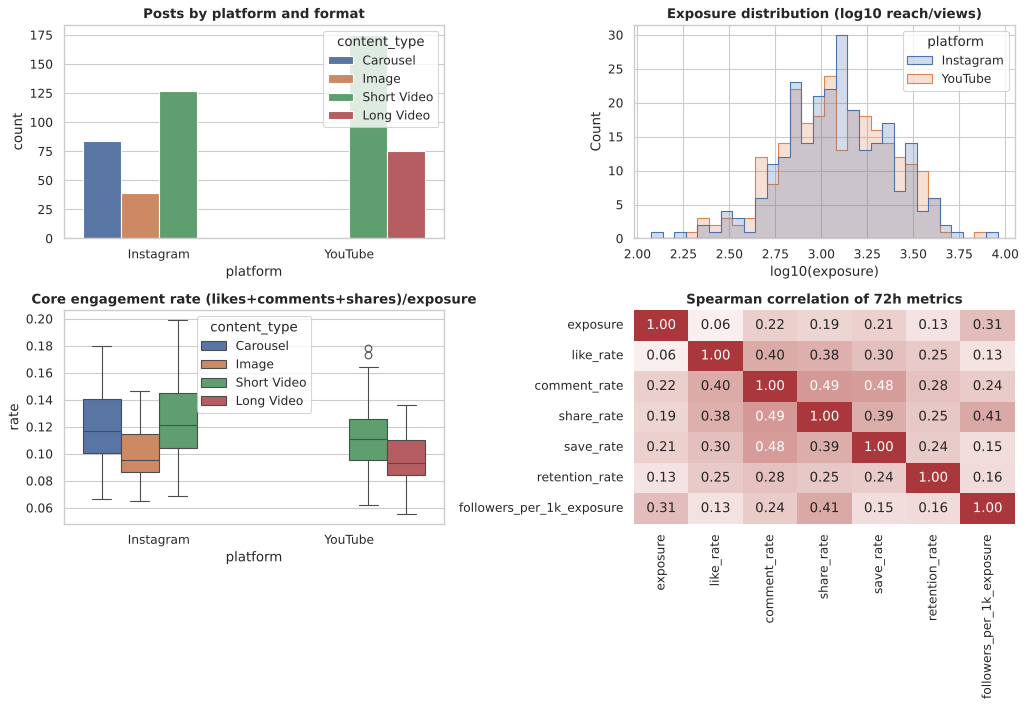

In [ ]:
overview = pd.DataFrame({
    'table': ['content', 'snapshots', 'comments', 'trends'],
    'rows': [len(content), len(snapshots), len(comments), len(trends)],
    'from': [content['publish_date'].min(), snapshots['snapshot_date'].min(), comments['comment_date'].min(), trends['observation_date'].min()],
    'to': [content['publish_date'].max(), snapshots['snapshot_date'].max(), comments['comment_date'].max(), trends['observation_date'].max()]})
display(overview)
metric_cols = ['views', 'reach', 'likes', 'comments', 'shares', 'saves', 'retention_rate', 'followers_gained']
print('Share of non-null values per platform (platform-specific metrics are expected to be null):')
display(analysis.groupby('platform')[metric_cols].agg(lambda s: s.notna().mean()).round(2))
display(analysis.groupby(['platform', 'content_type'])[['exposure', 'engagement_rate_core', 'share_rate', 'retention_rate']].median().round(4))

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
sns.countplot(data=analysis, x='platform', hue='content_type', ax=ax[0, 0]); ax[0, 0].set_title('Posts by platform and format')
sns.histplot(data=analysis, x=np.log10(analysis['exposure']), hue='platform', bins=30, ax=ax[0, 1], element='step')
ax[0, 1].set_title('Exposure distribution (log10 reach/views)'); ax[0, 1].set_xlabel('log10(exposure)')
sns.boxplot(data=analysis, x='platform', y='engagement_rate_core', hue='content_type', ax=ax[1, 0])
ax[1, 0].set_title('Core engagement rate (likes+comments+shares)/exposure'); ax[1, 0].set_ylabel('rate')
corr = analysis[['exposure', 'like_rate', 'comment_rate', 'share_rate', 'save_rate', 'retention_rate', 'followers_per_1k_exposure']].corr(method='spearman')
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0, ax=ax[1, 1], cbar=False); ax[1, 1].set_title('Spearman correlation of 72h metrics')
plt.tight_layout(); plt.show()

**Reading the EDA.** Platforms differ in which metrics exist and in the denominator used, so raw rates must not be compared across platforms without standardisation (done in Module 2). Rates are right-skewed, which motivates rank-based tests and bootstrap intervals later.

## 10. Module 1 — Content Performance Tracker
**Objective:** a consistent, validated, platform-aware log of content performance.
**Methodology:** (i) schema-checked ingestion and cleaning (Sections 6–7), (ii) cumulative snapshots at fixed ages, (iii) a single-post lookup, (iv) connector interfaces for real APIs.

Posts whose cumulative counters never decrease: 100.0%


,6,24,72,96
platform,Instagram,Instagram,Instagram,Instagram
topic,Self-Respect,Self-Respect,Self-Respect,Self-Respect
content_type,Carousel,Carousel,Carousel,Carousel
hook_type,Personal Story,Personal Story,Personal Story,Personal Story
data_source,SIMULATED,SIMULATED,SIMULATED,SIMULATED
views,38,143,405,531
reach,32.0,120.0,337.0,442.0
likes,4,14,38,49
comments,0,1,5,6
shares,1,4,11,15


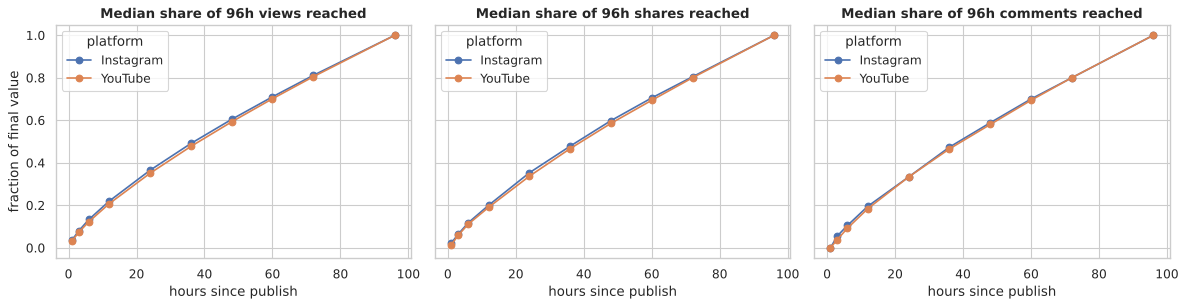

In [ ]:
final_snap = snapshots[snapshots['hours_since_publish'] == snapshots['hours_since_publish'].max()].set_index('content_id')
plat = content.set_index('content_id')['platform']
growth = snapshots.copy()
growth['platform'] = growth['content_id'].map(plat)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, metric in zip(axes, ['views', 'shares', 'comments']):
    final_val = growth['content_id'].map(final_snap[metric])
    growth['frac'] = safe_div(growth[metric], final_val)
    med = growth.groupby(['hours_since_publish', 'platform'])['frac'].median().unstack()
    med.plot(ax=ax, marker='o'); ax.set_title(f'Median share of 96h {metric} reached'); ax.set_xlabel('hours since publish')
axes[0].set_ylabel('fraction of final value'); plt.tight_layout(); plt.show()

mono = snapshots.sort_values(['content_id', 'hours_since_publish']).groupby('content_id')[['views', 'likes', 'comments', 'shares']].apply(
    lambda g: bool((g.diff().dropna() >= 0).all().all()))
print(f'Posts whose cumulative counters never decrease: {mono.mean():.1%}')

def content_performance_snapshot(content_id, hours=ANALYSIS_HOURS):
    """Look up one post's cumulative performance at a given age (the tracker 'read' API)."""
    row = snapshots[(snapshots['content_id'] == content_id) & (snapshots['hours_since_publish'] == hours)]
    if row.empty:
        raise KeyError(f'No snapshot for content_id={content_id} at {hours}h')
    meta = content[content['content_id'] == content_id].iloc[0]
    return pd.concat([meta[['platform', 'topic', 'content_type', 'hook_type', 'data_source']], row.iloc[0][COUNT_COLS + ['retention_rate', 'followers_gained']]])

display(pd.DataFrame({h: content_performance_snapshot(int(analysis['content_id'].iloc[0]), h) for h in [6, 24, 72, 96]}))

### 10.1 Platform connectors (interface only — **not implemented, not tested**)
The classes below fix the *contract* a real extractor must follow. They deliberately raise `NotImplementedError`: calling Instagram Graph / YouTube Data APIs needs OAuth credentials and app review that are not part of this project. `normalize_api_records` (the field-mapping step) **is** implemented and unit-tested offline on fake records. API metric names below are the expected ones — verify them against the current API documentation before use.

In [ ]:
YOUTUBE_METRIC_MAP = {'views': 'views', 'likes': 'likes', 'comments': 'comments', 'shares': 'shares', 'averageViewPercentage': 'retention_rate'}
INSTAGRAM_METRIC_MAP = {'views': 'views', 'reach': 'reach', 'likes': 'likes', 'comments': 'comments', 'shares': 'shares', 'saved': 'saves'}

def normalize_api_records(records, metric_map, data_source='REAL_API'):
    """Map raw API field names to the project snapshot schema. Pure function (no network)."""
    if data_source == 'SIMULATED':
        raise ValueError('API records can never be labelled SIMULATED')
    df = pd.DataFrame(records).rename(columns=metric_map)
    need = {'content_id', 'snapshot_date', 'hours_since_publish'}
    if not need.issubset(df.columns):
        raise ValueError(f'records must contain {sorted(need)}')
    for c in SCHEMAS['snapshots']['required'] + SCHEMAS['snapshots']['optional']:
        if c not in df.columns:
            df[c] = np.nan
    df['snapshot_date'] = pd.to_datetime(df['snapshot_date'])
    df['data_source'] = data_source
    return df

class PlatformConnector:
    """Contract for a data-extraction connector (one subclass per platform)."""
    platform = None
    metric_map = {}
    def fetch_content(self, since):       raise NotImplementedError('Needs API credentials - not implemented')
    def fetch_snapshots(self, content_ids): raise NotImplementedError('Needs API credentials - not implemented')

class YouTubeAnalyticsConnector(PlatformConnector):
    platform, metric_map = 'YouTube', YOUTUBE_METRIC_MAP
class InstagramGraphConnector(PlatformConnector):
    platform, metric_map = 'Instagram', INSTAGRAM_METRIC_MAP

try:
    InstagramGraphConnector().fetch_content(since='2026-01-01')
except NotImplementedError as exc:
    print('Connector status (expected):', exc)

Connector status (expected): Needs API credentials - not implemented


## 11. Module 2 — Virality Prediction
**Objective:** score every post with a transparent metric that favours high-value actions.

**Viral Engagement Score (VES)** = ( 3·shares + 2·comments + 1·likes ) / exposure   (`ves_core`, both platforms)
and `ves_full` additionally adds 3·saves (Instagram only).
* *Why these weights?* Shares and saves spread content to new people (organic growth); comments signal active resonance; likes are passive. The weights are **expert assumptions**, not estimated parameters — so a sensitivity analysis below checks that rankings do not depend on the exact values.
* *Why divide by exposure?* So a small post with a strong reaction ranks above a large post with a weak one.
* *Engagement score ≠ viral coefficient.* A true viral coefficient *k* = (invitations per user) × (conversion per invitation) needs referral tracking, which platform APIs do not expose. `viral_k_proxy` = shares per exposure × followers gained per share is the closest available proxy; algebraically it equals follower yield per exposure, so treat it as a proxy only.
* *Cross-platform comparison:* YouTube lacks saves and uses views, not reach, so `ves_core` is standardised **within platform** (z-score and percentile) before platforms are pooled.

In [ ]:
VES_WEIGHTS = {'shares': 3.0, 'saves': 3.0, 'comments': 2.0, 'likes': 1.0}

def viral_engagement_score(df, weights=VES_WEIGHTS, include_saves=False):
    num = weights['shares'] * df['shares'] + weights['comments'] * df['comments'] + weights['likes'] * df['likes']
    if include_saves:
        num = num + weights['saves'] * df['saves']      # NaN for YouTube -> NaN score (not 0)
    return safe_div(num, df['exposure'])

def add_virality_columns(df):
    df = df.copy()
    df['ves_core'] = viral_engagement_score(df)
    df['ves_full'] = viral_engagement_score(df, include_saves=True)
    g = df.groupby('platform')['ves_core']
    df['ves_core_z'] = (df['ves_core'] - g.transform('mean')) / g.transform('std')
    df['ves_core_pctile'] = g.rank(pct=True)
    df['top_performer'] = df['ves_core_pctile'] >= .80
    df['followers_per_share'] = safe_div(df['followers_gained'], df['shares'])
    df['viral_k_proxy'] = df['share_rate'] * df['followers_per_share']
    return df

analysis = add_virality_columns(analysis)
assert not np.isinf(analysis.select_dtypes('number')).any().any(), 'inf found in analysis table'
display(analysis.groupby('platform')[['ves_core', 'ves_full', 'ves_core_z', 'viral_k_proxy']].describe().T.round(4))

platform             Instagram   YouTube
ves_core      count   250.0000  250.0000
              mean      0.1843    0.1654
              std       0.0460    0.0357
              min       0.1002    0.0802
              25%       0.1493    0.1401
              50%       0.1771    0.1619
              75%       0.2145    0.1906
              max       0.3365    0.2874
ves_full      count   250.0000    0.0000
              mean      0.2775       NaN
              std       0.0653       NaN
              min       0.1452       NaN
              25%       0.2292       NaN
              50%       0.2703       NaN
              75%       0.3136       NaN
              max       0.5491       NaN
ves_core_z    count   250.0000  250.0000
              mean     -0.0000    0.0000
              std       1.0000    1.0000
              min      -1.8286   -2.3917
              25%      -0.7604   -0.7102
              50%      -0.1551   -0.0976
              75%       0.6568    0.7075
              max       3.3108    3.4220
viral_k_proxy count   250.0000  250.0000
              mean      0.0020    0.0020
              std       0.0020    0.0020
              min       0.0000    0.0000
              25%       0.0000    0.0000
              50%       0.0016    0.0017
              75%       0.0032    0.0030
              max       0.0079    0.0099

### 11.1 Weight sensitivity (is the ranking robust to the assumed weights?)

In [ ]:
schemes = {'default 3/2/1': (3, 2, 1), 'equal 1/1/1': (1, 1, 1), 'shares-heavy 5/2/1': (5, 2, 1), 'likes-heavy 1/1/3': (1, 1, 3)}
sens = {}
for name, (ws, wc, wl) in schemes.items():
    alt = safe_div(ws * analysis['shares'] + wc * analysis['comments'] + wl * analysis['likes'], analysis['exposure'])
    sens[name] = {p: stats.spearmanr(alt[m], analysis.loc[m, 'ves_core'])[0] for p, m in
                  {p: analysis['platform'] == p for p in PLATFORMS}.items()}
sens = pd.DataFrame(sens).T.rename(columns=lambda c: f'Spearman vs default ({c})').round(3)
display(sens)

,Spearman vs default (YouTube),Spearman vs default (Instagram)
default 3/2/1,1.000,1.000
equal 1/1/1,0.937,0.959
shares-heavy 5/2/1,0.985,0.992
likes-heavy 1/1/3,0.811,0.866


### 11.2 Which topics generate more engagement? (statistics, not eyeballing)
* Bootstrap 95% CI of the mean within-platform z-score per topic (2,000 resamples).
* **Kruskal–Wallis** test across topics (rank-based because VES is skewed) with effect size ε² = (H − k + 1)/(n − k).
* Interpretation rule: overlapping CIs / a non-significant test mean topics are **not** distinguishable with this sample.

Kruskal-Wallis across 10 topics: H=41.84, p=0.0000, epsilon^2=0.0670
=> topics DIFFER significantly at 5%.


,topic,n_posts,mean_ves_z,ci_low,ci_high,mean_ves_core,mean_share_rate,mean_followers_per_1k
0,Overthinking,50,0.6790,0.3946,0.9616,0.2017,0.0299,2.2229
1,Loneliness,45,0.3318,0.0480,0.6032,0.1860,0.0253,2.5347
2,Life Experiences,60,0.1703,-0.0515,0.3950,0.1822,0.0250,2.0867
3,Self-Respect,46,-0.0036,-0.2952,0.3315,0.1721,0.0245,1.7662
4,Social Anxiety,47,-0.0718,-0.3311,0.1867,0.1731,0.0240,2.2048
5,Dating & Relationships,47,-0.0903,-0.3880,0.2152,0.1738,0.0229,1.6444
6,Self-Improvement,46,-0.1708,-0.4162,0.0802,0.1698,0.0237,2.2649
7,Personal Growth,52,-0.1733,-0.4408,0.0859,0.1674,0.0231,1.6325
8,Mental Toughness,54,-0.2862,-0.5241,-0.0639,0.1627,0.0225,2.2530
9,Friendship,53,-0.3584,-0.5879,-0.1030,0.1606,0.0215,1.5407


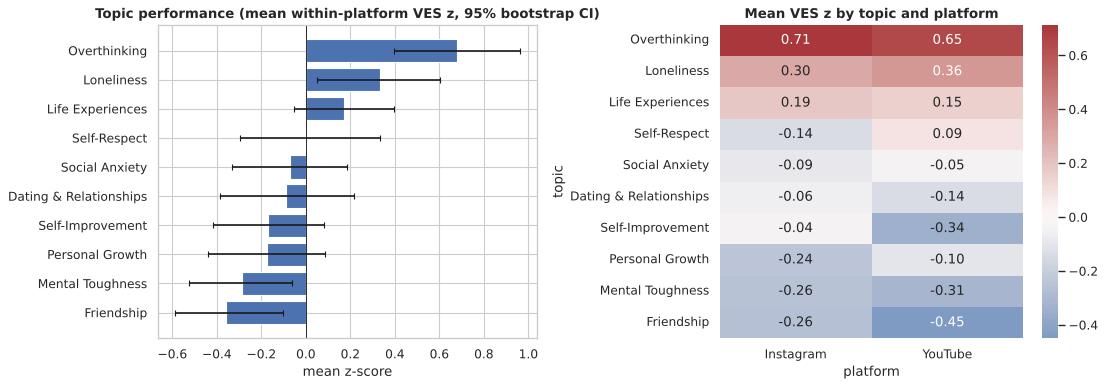

In [ ]:
def bootstrap_ci(values, n_boot=2000, alpha=.05, rng=None):
    v = np.asarray(values, float); v = v[~np.isnan(v)]
    rng = rng or rng_for('bootstrap')
    means = v[rng.integers(0, len(v), (n_boot, len(v)))].mean(axis=1)
    return np.quantile(means, [alpha / 2, 1 - alpha / 2])

rows = []
for topic, g in analysis.groupby('topic'):
    lo, hi = bootstrap_ci(g['ves_core_z'])
    rows.append({'topic': topic, 'n_posts': len(g), 'mean_ves_z': g['ves_core_z'].mean(), 'ci_low': lo, 'ci_high': hi,
                 'mean_ves_core': g['ves_core'].mean(), 'mean_share_rate': g['share_rate'].mean(),
                 'mean_followers_per_1k': g['followers_per_1k_exposure'].mean()})
topic_perf = pd.DataFrame(rows).sort_values('mean_ves_z', ascending=False).reset_index(drop=True)
groups = [g['ves_core_z'].dropna().to_numpy() for _, g in analysis.groupby('topic')]
H, p_kw = stats.kruskal(*groups)
k, n = len(groups), sum(len(g) for g in groups)
eps2 = (H - k + 1) / (n - k)
display(topic_perf.round(4))
print(f'Kruskal-Wallis across {k} topics: H={H:.2f}, p={p_kw:.4f}, epsilon^2={eps2:.4f}')
print('=> topics DIFFER significantly at 5%.' if p_kw < .05 else '=> no significant difference between topics at 5% with this sample.')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
t = topic_perf.iloc[::-1]
ax[0].barh(t['topic'], t['mean_ves_z'], xerr=[t['mean_ves_z'] - t['ci_low'], t['ci_high'] - t['mean_ves_z']], color='#4c72b0', capsize=3)
ax[0].axvline(0, color='k', lw=.8); ax[0].set_title('Topic performance (mean within-platform VES z, 95% bootstrap CI)'); ax[0].set_xlabel('mean z-score')
piv = analysis.pivot_table(index='topic', columns='platform', values='ves_core_z', aggfunc='mean').loc[topic_perf['topic']]
sns.heatmap(piv, annot=True, fmt='.2f', cmap='vlag', center=0, ax=ax[1]); ax[1].set_title('Mean VES z by topic and platform')
plt.tight_layout(); plt.show()

## 12. Module 3 — Audience Sentiment Analysis
**Objective:** tag comments as *Relatable* vs *Neutral/other* and measure sentiment polarity.
**Method:** normalised text → TF-IDF (1–2-grams; stop-words are **kept** because first-person words like "me", "I", "too" are linguistic triggers of relatability) → class-weighted Logistic Regression, compared with a majority-class baseline.

> **Integrity warning.** The comments are *synthetic*, generated from 33 phrase templates with random openers/closers, and the labels come from the generator (plus 6% random label noise) — **not from human annotators**. The scores below therefore measure *how well the pipeline learns the simulator*, and **must never be quoted as real-world NLP accuracy**. To make this visible, two evaluations are shown: a *text-grouped* split (no identical text in train and test) and a stricter *template-held-out* split where whole phrase templates are unseen.

In [ ]:
URL_RE = re.compile(r'(?:https?://|www\.)\S+', re.IGNORECASE)

def clean_text(text):
    """Lower-case, strip URLs/accents/emoji, keep hashtag words and apostrophes, collapse whitespace."""
    if text is None or (isinstance(text, float) and np.isnan(text)):
        return ''
    s = str(text).replace('\u2019', "'").replace('\u2018', "'")
    s = unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode('ascii').lower()
    s = URL_RE.sub(' ', s)
    s = re.sub(r'#(\w+)', r' \1 ', s)
    s = re.sub(r"[^a-z0-9\s']", ' ', s)
    return re.sub(r'\s+', ' ', s).strip()

for example in ["I CAN'T believe it!! https://x.com/a  ❤️", "Me too…   #relatable", "Café   vibes   www.site.org/x now"]:
    print(f'{example!r:48} -> {clean_text(example)!r}')

comments['clean_text'] = comments['comment_text'].map(clean_text)
comments = comments[comments['clean_text'] != ''].reset_index(drop=True)
HAS_LABELS = comments['relatability_label'].notna().sum() >= 200 and comments['relatability_label'].nunique() > 1
if not HAS_LABELS:
    raise RuntimeError('Module 3 needs a human-labelled subset of comments (relatability_label). Label >=200 comments and re-run.')
lab = comments[comments['relatability_label'].notna()].reset_index(drop=True)
lab['is_relatable'] = (lab['relatability_label'] == 'Relatable').astype(int)
print('\nLabel source(s):', sorted(lab['label_source'].dropna().unique()) if 'label_source' in lab else 'unknown')

"I CAN'T believe it!! https://x.com/a  ❤️"       -> "i can't believe it"
'Me too…   #relatable'                           -> 'me too relatable'
'Café   vibes   www.site.org/x now'              -> 'cafe vibes now'

Label source(s): ['SYNTHETIC_RULE']


### 12.1 Class balance

In [ ]:
bal = pd.DataFrame({'relatability_label': lab['relatability_label'].value_counts(),
                    'share': lab['relatability_label'].value_counts(normalize=True).round(3)})
bal2 = pd.DataFrame({'sentiment': lab['sentiment'].value_counts(), 'share': lab['sentiment'].value_counts(normalize=True).round(3)})
display(bal, bal2)
ratio = lab['is_relatable'].value_counts().max() / lab['is_relatable'].value_counts().min()
print(f'Binary imbalance ratio (majority/minority) = {ratio:.2f}  -> class_weight="balanced" is used; accuracy alone is not trusted, F1 is reported.')

Binary imbalance ratio (majority/minority) = 1.16  -> class_weight="balanced" is used; accuracy alone is not trusted, F1 is reported.


,relatability_label,share
relatability_label,,
Relatable,1387,0.462
Neutral,1157,0.386
Critical,456,0.152


,sentiment,share
sentiment,,
Positive,1461,0.487
Neutral,774,0.258
Negative,765,0.255


### 12.2 Training and evaluation

Reminder: SYNTHETIC data and generator labels. These numbers are a pipeline check, not real-world accuracy.


,task,evaluation,model,n_test,accuracy,precision,recall,f1
0,Relatable vs Neutral/other (binary),text-grouped split,Majority baseline,602,0.596,0.000,0.000,0.000
1,Relatable vs Neutral/other (binary),text-grouped split,TF-IDF + LogisticRegression,602,0.965,0.948,0.967,0.957
2,Relatable vs Neutral/other (binary),template-held-out split,Majority baseline,599,0.439,0.000,0.000,0.000
3,Relatable vs Neutral/other (binary),template-held-out split,TF-IDF + LogisticRegression,599,0.648,0.883,0.429,0.577
4,Sentiment (3-class),text-grouped split,Majority baseline,602,0.420,0.140,0.333,0.197
5,Sentiment (3-class),text-grouped split,TF-IDF + LogisticRegression,602,0.920,0.918,0.917,0.917
6,Sentiment (3-class),template-held-out split,Majority baseline,599,0.446,0.149,0.333,0.206
7,Sentiment (3-class),template-held-out split,TF-IDF + LogisticRegression,599,0.476,0.485,0.422,0.414


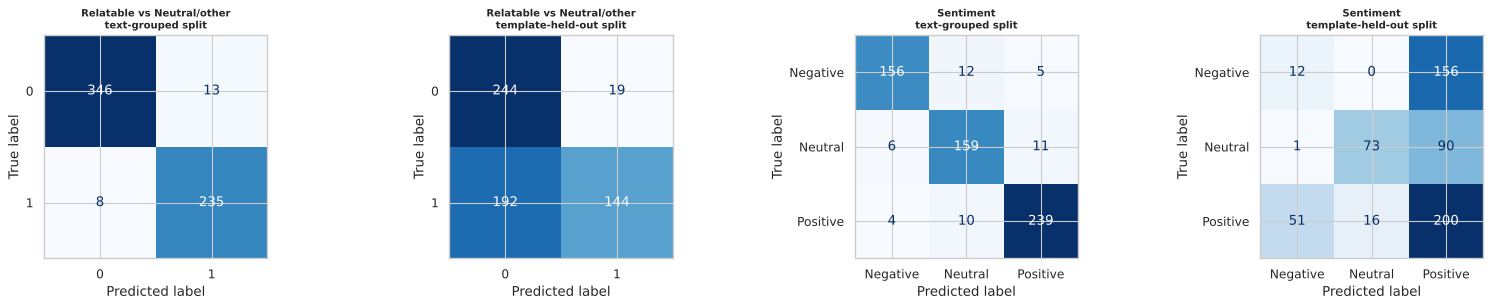

In [ ]:
def make_text_pipeline():
    return Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                     ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED))])

def metric_row(y_true, y_pred, positive=None):
    avg = 'binary' if positive is not None else 'macro'
    kw = dict(average=avg, zero_division=0, **({'pos_label': positive} if positive is not None else {}))
    return {'accuracy': accuracy_score(y_true, y_pred), 'precision': precision_score(y_true, y_pred, **kw),
            'recall': recall_score(y_true, y_pred, **kw), 'f1': f1_score(y_true, y_pred, **kw)}

splits = {'text-grouped split': lab['clean_text']}
if 'generator_template_id' in lab:
    splits['template-held-out split'] = lab['generator_template_id']

tasks = {'Relatable vs Neutral/other (binary)': ('is_relatable', 1), 'Sentiment (3-class)': ('sentiment', None)}
results, cms = [], {}
for task, (col, pos) in tasks.items():
    for split_name, groups_ in splits.items():
        tr, te = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEED).split(lab, lab[col], groups_))
        Xtr, Xte, ytr, yte = lab.loc[tr, 'clean_text'], lab.loc[te, 'clean_text'], lab.loc[tr, col], lab.loc[te, col]
        assert set(groups_.iloc[tr]).isdisjoint(set(groups_.iloc[te])), 'group leakage between train and test'
        base = DummyClassifier(strategy='most_frequent').fit(np.zeros((len(ytr), 1)), ytr)
        model = make_text_pipeline().fit(Xtr, ytr)
        pred = model.predict(Xte)
        results.append({'task': task, 'evaluation': split_name, 'model': 'Majority baseline', 'n_test': len(yte),
                        **metric_row(yte, base.predict(np.zeros((len(yte), 1))), pos)})
        results.append({'task': task, 'evaluation': split_name, 'model': 'TF-IDF + LogisticRegression', 'n_test': len(yte), **metric_row(yte, pred, pos)})
        cms[(task, split_name)] = (yte, pred)
nlp_results = pd.DataFrame(results)
display(nlp_results.round(3))
print('Reminder: SYNTHETIC data and generator labels. These numbers are a pipeline check, not real-world accuracy.')

fig, axes = plt.subplots(1, len(cms), figsize=(5 * len(cms), 4))
for ax, ((task, split_name), (yt, yp)) in zip(np.atleast_1d(axes), cms.items()):
    ConfusionMatrixDisplay.from_predictions(yt, yp, ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{task.split(" (")[0]}\n{split_name}', fontsize=9)
plt.tight_layout(); plt.show()

**Interpretation.** Versus the majority-class baseline the model clearly learns signal, and the confusion matrices show where it errs. The **template-held-out** rows are the honest warning: once the exact phrases are unseen, recall for *Relatable* and the 3-class sentiment F1 both drop sharply, because TF-IDF can only score words it has seen. Real comments are far more varied than 33 templates, so real performance would have to be measured on a human-labelled hold-out set — which this project does not have.

### 12.3 Linguistic triggers, tagging script and out-of-fold scoring
* Top coefficients show which words the model associates with *Relatable* (the "linguistic triggers" in the brief).
* To score **every** comment without scoring training data, 5-fold *grouped* cross-validation produces **out-of-fold** probabilities.
* `tag_comments` is the deliverable script that tags new comments as Relatable / Neutral.

In [ ]:
rel_model = make_text_pipeline().fit(lab['clean_text'], lab['is_relatable'])
sent_model = make_text_pipeline().fit(lab['clean_text'], lab['sentiment'])
vocab = np.array(rel_model.named_steps['tfidf'].get_feature_names_out()); coef = rel_model.named_steps['clf'].coef_[0]
order = np.argsort(coef)
display(pd.DataFrame({'toward Relatable': vocab[order[::-1][:10]], 'weight+': coef[order[::-1][:10]].round(2),
                      'toward Neutral/other': vocab[order[:10]], 'weight-': coef[order[:10]].round(2)}))

gkf = GroupKFold(n_splits=5)
oof_prob = cross_val_predict(make_text_pipeline(), lab['clean_text'], lab['is_relatable'], groups=lab['clean_text'], cv=gkf, method='predict_proba')[:, 1]
oof_sent = cross_val_predict(make_text_pipeline(), lab['clean_text'], lab['sentiment'], groups=lab['clean_text'], cv=gkf)
lab['relatable_prob'] = oof_prob
lab['pred_tag'] = np.where(oof_prob >= .5, 'Relatable', 'Neutral')
lab['pred_sentiment'] = oof_sent

def tag_comments(texts, model=rel_model, threshold=.5):
    """Tag raw comment strings as 'Relatable' or 'Neutral' with the trained baseline model."""
    cleaned = [clean_text(t) for t in texts]
    prob = model.predict_proba(cleaned)[:, 1]
    return pd.DataFrame({'comment': list(texts), 'tag': np.where(prob >= threshold, 'Relatable', 'Neutral'), 'relatable_prob': prob.round(3)})

display(tag_comments(["Honestly I feel this every day", "What mic do you use for recording?", "this is literally me lol", "Great lighting in this video"]))

comments_scored = lab.merge(content[['content_id', 'platform', 'topic', 'content_type', 'hook_type', 'publish_date']], on='content_id', how='left', validate='many_to_one')
joblib.dump(rel_model, DIRS['models'] / 'relatability_classifier.joblib')
joblib.dump(sent_model, DIRS['models'] / 'sentiment_classifier.joblib')

,toward Relatable,weight+,toward Neutral/other,weight-
0,today,2.18,part,-1.34
1,my,2.03,of,-1.32
2,it,1.96,everyone,-1.29
3,needed this,1.90,perspective,-1.27
4,this today,1.90,interesting perspective,-1.27
5,me,1.77,interesting,-1.27
6,who,1.76,nice,-1.21
7,this for,1.63,this differently,-1.15
8,to,1.53,see this,-1.15
9,needed,1.43,differently,-1.15


,comment,tag,relatable_prob
0,Honestly I feel this every day,Relatable,0.577
1,What mic do you use for recording?,Neutral,0.123
2,this is literally me lol,Relatable,0.882
3,Great lighting in this video,Neutral,0.109


### 12.4 Relatability by topic
Does the share of relatable comments differ across topics? Out-of-fold predicted tags are used (the situation for unlabelled real comments); a chi-square test of independence and Cramér's V quantify the difference.

Chi-square topic x predicted tag: chi2=83.6, dof=9, p=3.08e-14, Cramer's V=0.167


,n_comments,relatable_share_pred,relatable_share_label,mean_relatable_prob
topic,,,,
Loneliness,298,0.644,0.621,0.605
Social Anxiety,307,0.570,0.537,0.550
Overthinking,361,0.546,0.526,0.526
Dating & Relationships,293,0.481,0.474,0.476
Personal Growth,270,0.459,0.430,0.452
Friendship,245,0.441,0.437,0.444
Life Experiences,441,0.433,0.420,0.436
Self-Respect,228,0.430,0.417,0.433
Self-Improvement,268,0.392,0.384,0.401


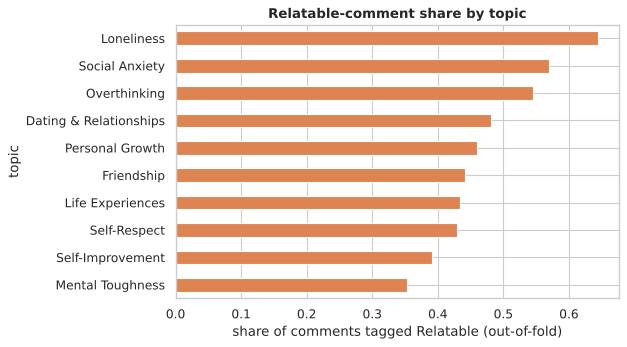

In [ ]:
tab = pd.crosstab(comments_scored['topic'], comments_scored['pred_tag'])
chi2, p_chi, dof, _ = stats.chi2_contingency(tab)
cramers_v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
rel_topic = comments_scored.groupby('topic').agg(n_comments=('comment_id', 'size'), relatable_share_pred=('pred_tag', lambda s: (s == 'Relatable').mean()),
                                                 relatable_share_label=('is_relatable', 'mean'), mean_relatable_prob=('relatable_prob', 'mean')).sort_values('relatable_share_pred', ascending=False)
display(rel_topic.round(3))
print(f'Chi-square topic x predicted tag: chi2={chi2:.1f}, dof={dof}, p={p_chi:.2e}, Cramer\'s V={cramers_v:.3f}')
fig, ax = plt.subplots(figsize=(8, 4.5))
rel_topic['relatable_share_pred'].iloc[::-1].plot.barh(ax=ax, color='#dd8452'); ax.set_xlabel('share of comments tagged Relatable (out-of-fold)')
ax.set_title('Relatable-comment share by topic'); plt.tight_layout(); plt.show()

## 13. Module 4 — A/B Testing Framework
**Objective:** decide which content variables (hook, format, caption, posting time) change engagement, with correct statistics and honest limits.

**Two different situations are kept strictly apart:**
1. **Observational comparison of historical posts** (Part B). Variants were *not* randomly assigned, so a significant result is an *association*, never proof of cause (platform, topic or time-of-day mix can differ between groups).
2. **A properly randomised experiment** (Parts A, C, D): stratified random assignment, pre-registered metric, power-based sample size. Here no real experiment has been run, so the framework is validated by **simulation** with a known effect.

**Metrics.** Primary: `ves_core_z` (VES standardised within platform). Secondary: `share_rate`, `comment_rate`, `retention_rate` (video only), `followers_per_1k_exposure`.
**Statistics.** Welch's t-test (no equal-variance assumption) with the Welch–Satterthwaite CI, Cohen's d with CI, Hedges' g, Mann–Whitney U as a rank-based robustness check, Holm correction for multiple primary tests.

In [ ]:
def cohens_d(a, b):
    """Standardised mean difference (b - a) using the pooled SD, with a normal-approximation 95% CI."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    d = (b.mean() - a.mean()) / sp
    se = np.sqrt((na + nb) / (na * nb) + d ** 2 / (2 * (na + nb)))
    return d, d - 1.96 * se, d + 1.96 * se

def welch_test(a, b, alpha=.05):
    """Two-sample comparison of b (treatment) vs a (control)."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    na, nb = len(a), len(b)
    if min(na, nb) < 3:
        raise ValueError('Each group needs at least 3 observations')
    va, vb = a.var(ddof=1) / na, b.var(ddof=1) / nb
    diff, se = b.mean() - a.mean(), np.sqrt(va + vb)
    df = (va + vb) ** 2 / (va ** 2 / (na - 1) + vb ** 2 / (nb - 1))        # Welch-Satterthwaite
    t_stat, p = stats.ttest_ind(b, a, equal_var=False)
    crit = stats.t.ppf(1 - alpha / 2, df)
    d, d_lo, d_hi = cohens_d(a, b)
    g = d * (1 - 3 / (4 * (na + nb) - 9))                                   # Hedges' small-sample correction
    return {'n_control': na, 'n_treatment': nb, 'mean_control': a.mean(), 'mean_treatment': b.mean(), 'diff': diff,
            'ci_low': diff - crit * se, 'ci_high': diff + crit * se, 't': t_stat, 'df': df, 'p_value': p,
            'cohens_d': d, 'd_ci_low': d_lo, 'd_ci_high': d_hi, 'hedges_g': g, 'mannwhitney_p': stats.mannwhitneyu(a, b).pvalue}

def assumption_checks(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    return {'skew_control': stats.skew(a), 'skew_treatment': stats.skew(b), 'shapiro_p_control': stats.shapiro(a).pvalue,
            'shapiro_p_treatment': stats.shapiro(b).pvalue, 'levene_p': stats.levene(a, b).pvalue}

def power_two_sample(d, n_per_group, alpha=.05):
    """Power of a two-sided two-sample t-test (equal n) via the non-central t distribution."""
    df, ncp = 2 * n_per_group - 2, d * np.sqrt(n_per_group / 2)
    crit = stats.t.ppf(1 - alpha / 2, df)
    lower = np.nan_to_num(stats.nct.cdf(-crit, df, ncp), nan=0.0)          # opposite tail is ~0 and can be numerically NaN for large ncp
    return float(stats.nct.sf(crit, df, ncp) + lower)

def required_n_per_group(d, power=.80, alpha=.05):
    n = 3
    while power_two_sample(d, n, alpha) < power:
        n += 1
    return n

def minimum_detectable_d(n_per_group, power=.80, alpha=.05):
    from scipy.optimize import brentq
    f = lambda d: power_two_sample(d, n_per_group, alpha) - power
    return brentq(f, 1e-3, 3.0) if f(3.0) > 0 else np.inf          # bracket kept inside the range where the non-central t is numerically stable

def assign_variants(df, strata_cols, seed, arms=('A', 'B')):
    """Stratified (blocked) random assignment: within each stratum posts are shuffled and alternated between arms."""
    rng = np.random.default_rng(seed)
    out = pd.Series(index=df.index, dtype=object)
    for _, g0 in df.groupby(strata_cols):
        idx = g0.index.to_numpy().copy(); rng.shuffle(idx)
        first = int(rng.integers(len(arms)))
        out.loc[idx] = [arms[(i + first) % len(arms)] for i in range(len(idx))]
    return out

print('d=0.5, 80% power ->', required_n_per_group(.5), 'per group (textbook value: 64)')

d=0.5, 80% power -> 64 per group (textbook value: 64)


### 13.1 Part A — Experiment design and sample-size planning
Required sample per arm to detect small / medium / large standardised effects, and the minimum effect each *historical* comparison below could detect with the data actually available.

In [ ]:
plan = pd.DataFrame({'target effect (Cohen d)': [.2, .3, .5, .8]})
plan['n per arm (80% power, alpha=.05)'] = plan['target effect (Cohen d)'].map(required_n_per_group)
plan['n per arm (90% power)'] = plan['target effect (Cohen d)'].map(lambda d: required_n_per_group(d, .90))
display(plan)

EXPERIMENTS = pd.DataFrame([
    ('E1', 'Hook: Personal Story vs Question', 'hook_type', 'Question', 'Personal Story', 'all', 'two-sided'),
    ('E2', 'Caption: Storytelling vs Educational', 'caption_style', 'Educational', 'Storytelling', 'all', 'two-sided'),
    ('E3', 'Format: Short vs Long video', 'content_type', 'Long Video', 'Short Video', 'YouTube', 'two-sided'),
    ('E4', 'Posting time: Evening vs Morning', 'posting_slot', 'Morning', 'Evening', 'all', 'two-sided'),
    ('E5', 'Topic: Social Anxiety vs Dating & Relationships', 'topic', 'Dating & Relationships', 'Social Anxiety', 'all', 'two-sided'),
    ('E6', 'Duration (short videos): <=45s vs >45s', 'duration_seconds', '>45s', '<=45s', 'Short Video', 'two-sided')],
    columns=['experiment_id', 'name', 'variable', 'control', 'treatment', 'scope', 'hypothesis'])
EXPERIMENTS['primary_metric'] = 'ves_core_z'
EXPERIMENTS['secondary_metrics'] = 'share_rate;comment_rate;retention_rate;followers_per_1k_exposure'
EXPERIMENTS['alpha'] = .05
EXPERIMENTS['planned_n_per_arm_d0.3'] = required_n_per_group(.3)
display(EXPERIMENTS[['experiment_id', 'name', 'variable', 'control', 'treatment', 'scope', 'primary_metric']])

,target effect (Cohen d),"n per arm (80% power, alpha=.05)",n per arm (90% power)
0,0.2,394,527
1,0.3,176,235
2,0.5,64,86
3,0.8,26,34


,experiment_id,name,variable,control,treatment,scope,primary_metric
0,E1,Hook: Personal Story vs Question,hook_type,Question,Personal Story,all,ves_core_z
1,E2,Caption: Storytelling vs Educational,caption_style,Educational,Storytelling,all,ves_core_z
2,E3,Format: Short vs Long video,content_type,Long Video,Short Video,YouTube,ves_core_z
3,E4,Posting time: Evening vs Morning,posting_slot,Morning,Evening,all,ves_core_z
4,E5,Topic: Social Anxiety vs Dating & Relationships,topic,Dating & Relationships,Social Anxiety,all,ves_core_z
5,E6,Duration (short videos): <=45s vs >45s,duration_seconds,>45s,<=45s,Short Video,ves_core_z


### 13.2 Part B — Observational analysis of historical posts
Experiment definitions are fixed *before* looking at results (listed above). Each is tested on the primary metric, then secondary metrics are reported descriptively. **Holm correction** controls the family-wise error across the six primary tests.

,experiment_id,name,n_control,n_treatment,diff,ci_low,ci_high,p_value,p_holm,cohens_d,d_ci_low,d_ci_high,mannwhitney_p,mde_d_at_observed_n,significant_after_holm
0,E1,Hook: Personal Story vs Question,122,113,0.0542,-0.2058,0.3142,0.6817,1.0000,0.0537,-0.2023,0.3096,0.6061,0.3743,False
1,E2,Caption: Storytelling vs Educational,123,132,0.1810,-0.0686,0.4307,0.1546,0.6182,0.1785,-0.0676,0.4246,0.1809,0.3587,False
2,E3,Format: Short vs Long video,75,175,0.6861,0.4478,0.9243,0.0000,0.0000,0.7214,0.4436,0.9992,0.0000,0.4605,True
3,E4,Posting time: Evening vs Morning,147,115,0.3070,0.0551,0.5589,0.0171,0.0855,0.2996,0.0542,0.5449,0.0091,0.3710,False
4,E5,Topic: Social Anxiety vs Dating & Relationships,47,47,0.0184,-0.3930,0.4299,0.9293,1.0000,0.0183,-0.3860,0.4227,0.8088,0.5840,False
5,E6,Duration (short videos): <=45s vs >45s,173,129,0.1398,-0.0899,0.3695,0.2320,0.6959,0.1390,-0.0893,0.3672,0.2326,0.3502,False


,experiment_id,metric,diff,p_value,cohens_d
0,E1,share_rate,0.0007,0.4826,0.0920
1,E1,comment_rate,-0.0004,0.5099,-0.0861
2,E1,retention_rate,1.5416,0.5498,0.0901
3,E1,followers_per_1k_exposure,-0.1221,0.6329,-0.0627
4,E2,share_rate,0.0000,0.9703,0.0047
5,E2,comment_rate,0.0009,0.1466,0.1817
6,E2,retention_rate,0.7146,0.7476,0.0450
7,E2,followers_per_1k_exposure,0.1183,0.6354,0.0598
8,E3,share_rate,0.0037,0.0001,0.5218
9,E3,comment_rate,0.0029,0.0000,0.6842


,experiment_id,skew_control,skew_treatment,shapiro_p_control,shapiro_p_treatment,levene_p
0,E1,0.408,0.547,0.030,0.060,0.852
1,E2,0.408,0.457,0.053,0.012,0.499
2,E3,-0.056,0.536,0.136,0.005,0.124
3,E4,0.614,0.576,0.000,0.020,0.980
4,E5,0.521,0.111,0.365,0.151,0.968
5,E6,0.453,0.580,0.037,0.004,0.807


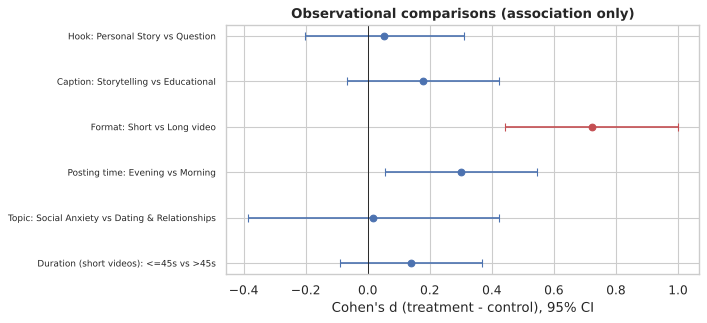

In [ ]:
SECONDARY = ['share_rate', 'comment_rate', 'retention_rate', 'followers_per_1k_exposure']

def select_groups(df, exp):
    d = df
    if exp.scope == 'YouTube':
        d = d[d['platform'] == 'YouTube']
    elif exp.scope == 'Short Video':
        d = d[d['content_type'] == 'Short Video']
    if exp.variable == 'duration_seconds':
        return d[d['duration_seconds'] > 45], d[d['duration_seconds'] <= 45]
    return d[d[exp.variable] == exp.control], d[d[exp.variable] == exp.treatment]

def holm(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p)
    adj = np.empty(m); running = 0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i]); adj[i] = min(1, running)
    return adj

rows, sec_rows = [], []
for exp in EXPERIMENTS.itertuples():
    ctrl, trt = select_groups(analysis, exp)
    r = welch_test(ctrl[exp.primary_metric], trt[exp.primary_metric])
    r.update(experiment_id=exp.experiment_id, name=exp.name,
             mde_d_at_observed_n=minimum_detectable_d(int(min(r['n_control'], r['n_treatment']))))
    rows.append(r)
    for m in SECONDARY:
        if ctrl[m].notna().sum() >= 3 and trt[m].notna().sum() >= 3:
            s = welch_test(ctrl[m], trt[m]); sec_rows.append({'experiment_id': exp.experiment_id, 'metric': m, 'diff': s['diff'], 'p_value': s['p_value'], 'cohens_d': s['cohens_d']})
ab = pd.DataFrame(rows)
ab['p_holm'] = holm(ab['p_value'])
ab['significant_after_holm'] = ab['p_holm'] < .05
ab['evidence_type'] = 'observational association (no randomisation)'
cols = ['experiment_id', 'name', 'n_control', 'n_treatment', 'diff', 'ci_low', 'ci_high', 'p_value', 'p_holm', 'cohens_d', 'd_ci_low', 'd_ci_high',
        'mannwhitney_p', 'mde_d_at_observed_n', 'significant_after_holm']
display(ab[cols].round(4))
display(pd.DataFrame(sec_rows).round(4))

chk = pd.DataFrame([{'experiment_id': e.experiment_id, **assumption_checks(*[g[e.primary_metric] for g in select_groups(analysis, e)])} for e in EXPERIMENTS.itertuples()])
display(chk.round(3))

fig, ax = plt.subplots(figsize=(9, 4.2))
y = np.arange(len(ab))[::-1]
for yi, r in zip(y, ab.itertuples()):
    ax.errorbar(r.cohens_d, yi, xerr=[[r.cohens_d - r.d_ci_low], [r.d_ci_high - r.cohens_d]], fmt='o', capsize=4,
                color='#c44e52' if r.significant_after_holm else '#4c72b0')
ax.axvline(0, color='k', lw=.8); ax.set_yticks(y); ax.set_yticklabels(ab['name'], fontsize=8)
ax.set_xlabel("Cohen's d (treatment - control), 95% CI"); ax.set_title('Observational comparisons (association only)'); plt.tight_layout(); plt.show()

**How to read Part B.** `mde_d_at_observed_n` is the smallest effect each comparison could reliably detect (80% power); comparisons whose observed |d| is below it are *under-powered*, so "not significant" means **inconclusive**, not "no effect". A confidence interval spanning 0 with a wide range says the same. Significant results are associations: posts with each variant also differ in platform/topic/format mix, so causality is **not** established.

### 13.3 Part C — Does the framework behave correctly? (Monte-Carlo operating characteristics)
Draw 2,000 simulated experiments per scenario. With **no true effect (A/A)** the test should reject about 5% of the time (type-I error); with a true effect the rejection rate is the empirical **power**, which should match the theoretical value. Skewed (log-normal) outcomes check Welch's robustness.

In [ ]:
def monte_carlo(d, n, sims=2000, skewed=False, rng=None):
    rng = rng or rng_for('mc')
    if skewed:
        sigma = .6; a = rng.lognormal(0, sigma, (sims, n)); b = rng.lognormal(0, sigma, (sims, n))
        shift = d * a.std()                         # shift on the natural scale -> effect of roughly d SDs
        b = b + shift
    else:
        a = rng.normal(0, 1, (sims, n)); b = rng.normal(d, 1, (sims, n))
    p = stats.ttest_ind(b, a, axis=1, equal_var=False).pvalue
    return (p < .05).mean()

mc_rows = []
for d in [0, .2, .3, .5]:
    for n in [50, required_n_per_group(.3)]:
        mc_rows.append({'true d': d, 'n per arm': n, 'empirical rejection rate (normal)': monte_carlo(d, n),
                        'empirical rejection rate (skewed)': monte_carlo(d, n, skewed=True),
                        'theoretical power': power_two_sample(d, n) if d > 0 else .05})
mc = pd.DataFrame(mc_rows)
display(mc.round(3))
type1 = mc[mc['true d'] == 0]['empirical rejection rate (normal)']
print(f'Type-I error with no true effect: {type1.min():.3f}-{type1.max():.3f} (nominal 0.05)')

Type-I error with no true effect: 0.038-0.051 (nominal 0.05)


,true d,n per arm,empirical rejection rate (normal),empirical rejection rate (skewed),theoretical power
0,0.0,50,0.038,0.040,0.050
1,0.0,176,0.052,0.051,0.050
2,0.2,50,0.166,0.180,0.168
3,0.2,176,0.456,0.473,0.465
4,0.3,50,0.316,0.332,0.318
5,0.3,176,0.806,0.806,0.801
6,0.5,50,0.679,0.700,0.697
7,0.5,176,0.997,0.996,0.997


### 13.4 Part D — End-to-end *simulated* randomised experiment
Hook A = *Question*, Hook B = *Personal Story*. New simulated posts are **randomly assigned** (stratified by platform and topic) using the planned sample size for d = 0.3, outcomes are generated by the same simulator and analysed with the same pipeline. The true effect is known to the simulator but is *small*, so the experiment is deliberately realistic: it may or may not reach significance, and the result is reported whatever it is.

In [ ]:
n_arm = required_n_per_group(.3)
rct = simulate_content(2 * n_arm, rng_for('rct_content'))
rct['variant'] = assign_variants(rct, ['platform', 'topic'], seed=SEED)
rct['hook_type'] = rct['variant'].map({'A': 'Question', 'B': 'Personal Story'})
balance = rct.groupby('variant')[['duration_seconds']].mean().join(rct.groupby('variant')['platform'].apply(lambda s: (s == 'Instagram').mean()).rename('share_instagram'))
display(balance.round(3))
rct_snap = simulate_snapshots(rct, rng_for('rct_snapshots'))
rct_an = add_virality_columns(build_analysis_table(rct, rct_snap))
rct_an['variant'] = rct_an['content_id'].map(rct.set_index('content_id')['variant'])
res = welch_test(rct_an.loc[rct_an['variant'] == 'A', 'ves_core_z'], rct_an.loc[rct_an['variant'] == 'B', 'ves_core_z'])
display(pd.DataFrame([res]).round(4).T.rename(columns={0: 'primary metric: ves_core_z'}))
true_ratio = TRUE_EFFECTS['hook_type']['Personal Story'] / TRUE_EFFECTS['hook_type']['Question']
print(f'Simulator ground truth: Personal Story multiplies high-value-action rates by {true_ratio:.3f} vs Question (a small effect).')
print('Result:', 'significant at 5% (randomised design -> causal within the simulation).' if res['p_value'] < .05 else
      'not significant at 5% - the experiment is under-powered for an effect this small; this is the expected outcome for small true effects.')

Simulator ground truth: Personal Story multiplies high-value-action rates by 1.019 vs Question (a small effect).
Result: not significant at 5% - the experiment is under-powered for an effect this small; this is the expected outcome for small true effects.


,duration_seconds,share_instagram
variant,,
A,107.938,0.503
B,84.286,0.497


,primary metric: ves_core_z
n_control,177.0000
n_treatment,175.0000
mean_control,-0.0275
mean_treatment,0.0278
diff,0.0552
ci_low,-0.1544
ci_high,0.2649
t,0.5180
df,348.8930
p_value,0.6048


## 14. Module 5 — Engagement Optimization Recommender
**Objective:** recommend the topic, format, duration, hook, caption style and posting slot with the highest expected engagement for the coming week.

**Design (leakage control).**
* **Target:** `ves_core` at 72h.
* **Inputs (all known before publishing):** platform, topic, format, hook, caption style, posting slot, duration, caption length, hashtag count, plus *historical* mean VES of the same platform×topic and platform×hook computed **only from posts published at least 72 hours earlier** — a post's own outcome and any outcome not yet observable at its publication time are never used.
* **Validation:** chronological split — train on the earliest 80% of posts, test on the latest 20%, with a 72-hour purge gap; model choice by time-series cross-validation on the training period only; the test set is scored once.
* **Models:** mean baseline → platform-only linear (both *references*) → Ridge (all features) → Random Forest (captures interactions). The recommender must react to content attributes, so the final model is chosen between Ridge and Random Forest only; baselines show whether the added features help. Metrics: MAE, RMSE, R².

In [ ]:
def lagged_group_mean(df, group_cols, value_col, time_col='publish_date', lag_hours=72, ref_times=None):
    """Mean of `value_col` over earlier posts in the same group that were published >= lag_hours before each reference time.
    Only past, already-observable information is used (no look-ahead)."""
    out = pd.Series(np.nan, index=df.index)
    ref = df[time_col] if ref_times is None else ref_times
    for _, g0 in df.groupby(group_cols):
        g = g0.sort_values(time_col)
        times = g[time_col].to_numpy(); cs = g[value_col].fillna(0).cumsum().to_numpy()
        cutoff = (ref.loc[g.index] - pd.Timedelta(hours=lag_hours)).to_numpy()
        pos = np.searchsorted(times, cutoff, side='right')
        out.loc[g.index] = np.where(pos > 0, cs[np.maximum(pos - 1, 0)] / np.maximum(pos, 1), np.nan)
    return out

model_df = analysis.sort_values('publish_date').reset_index(drop=True)
model_df['hist_platform_topic_ves'] = lagged_group_mean(model_df, ['platform', 'topic'], 'ves_core')
model_df['hist_platform_hook_ves'] = lagged_group_mean(model_df, ['platform', 'hook_type'], 'ves_core')
CAT = ['platform', 'topic', 'content_type', 'hook_type', 'caption_style', 'posting_slot']
NUM = ['duration_seconds', 'caption_length_words', 'hashtag_count', 'hist_platform_topic_ves', 'hist_platform_hook_ves']
FEATURES, TARGET = CAT + NUM, 'ves_core'
OUTCOME_COLS = {'views', 'reach', 'likes', 'comments', 'shares', 'saves', 'retention_rate', 'followers_gained', 'exposure', 'ves_core', 'ves_full',
                'ves_core_z', 'ves_core_pctile', 'top_performer', 'engagement_rate_core', 'engagement_rate_full', 'share_rate', 'save_rate', 'comment_rate',
                'like_rate', 'save_to_share_ratio', 'followers_per_1k_exposure', 'viral_k_proxy', 'followers_per_share', 'core_interactions'}
assert not set(FEATURES) & OUTCOME_COLS, 'target leakage: outcome column used as feature'

split_idx = int(len(model_df) * .8)
split_time = model_df.loc[split_idx, 'publish_date']
train = model_df[model_df['publish_date'] < split_time - pd.Timedelta(hours=72)]        # purge gap
test = model_df.iloc[split_idx:]
assert train['publish_date'].max() < test['publish_date'].min()
print(f'train: {len(train)} posts ({train["publish_date"].min():%Y-%m-%d} to {train["publish_date"].max():%Y-%m-%d}) | '
      f'test: {len(test)} posts ({test["publish_date"].min():%Y-%m-%d} to {test["publish_date"].max():%Y-%m-%d}) | purged: {len(model_df)-len(train)-len(test)}')

def make_pre(cat, num):
    return ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat),
                              ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num)])

candidates = {
    'Mean baseline': Pipeline([('pre', make_pre([], ['duration_seconds'])), ('m', DummyRegressor(strategy='mean'))]),
    'Platform-only linear': Pipeline([('pre', make_pre(['platform'], [])), ('m', Ridge(alpha=1.0))]),
    'Ridge (all features)': Pipeline([('pre', make_pre(CAT, NUM)), ('m', Ridge(alpha=10.0))]),
    'Random Forest': Pipeline([('pre', make_pre(CAT, NUM)), ('m', RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1))])}

def reg_metrics(y, p):
    return {'MAE': mean_absolute_error(y, p), 'RMSE': np.sqrt(mean_squared_error(y, p)), 'R2': r2_score(y, p)}

tscv = TimeSeriesSplit(n_splits=4, gap=20)
rows = []
for name, pipe in candidates.items():
    cv = []
    for tr_i, va_i in tscv.split(train):
        pipe.fit(train.iloc[tr_i][FEATURES], train.iloc[tr_i][TARGET]); cv.append(reg_metrics(train.iloc[va_i][TARGET], pipe.predict(train.iloc[va_i][FEATURES])))
    cv = pd.DataFrame(cv)
    pipe.fit(train[FEATURES], train[TARGET]); te = reg_metrics(test[TARGET], pipe.predict(test[FEATURES]))
    rows.append({'model': name, 'CV MAE': cv['MAE'].mean(), 'CV RMSE': cv['RMSE'].mean(), 'CV R2': cv['R2'].mean(),
                 'test MAE': te['MAE'], 'test RMSE': te['RMSE'], 'test R2': te['R2']})
model_metrics = pd.DataFrame(rows)
ELIGIBLE = ['Ridge (all features)', 'Random Forest']          # a recommender must respond to content attributes, so baselines are references only
elig = model_metrics[model_metrics['model'].isin(ELIGIBLE)]
best_name = elig.loc[elig['CV RMSE'].idxmin(), 'model']
display(model_metrics.round(4))
print(f'Selected among attribute-aware models by time-series CV RMSE (training period only): {best_name}')
ref = model_metrics.set_index('model')
print('Does it beat the mean baseline on the untouched test period (RMSE)?', bool(ref.loc[best_name, 'test RMSE'] < ref.loc['Mean baseline', 'test RMSE']))
print('Data are SYNTHETIC: R2 describes how learnable the simulator is, not real-world predictability.')

train: 383 posts (2026-07-30 to 2026-10-07) | test: 100 posts (2026-10-10 to 2026-10-27) | purged: 17
Selected among attribute-aware models by time-series CV RMSE (training period only): Ridge (all features)
Does it beat the mean baseline on the untouched test period (RMSE)? True
Data are SYNTHETIC: R2 describes how learnable the simulator is, not real-world predictability.


,model,CV MAE,CV RMSE,CV R2,test MAE,test RMSE,test R2
0,Mean baseline,0.0337,0.0416,-0.0324,0.0355,0.0450,-0.0000
1,Platform-only linear,0.0327,0.0403,0.0310,0.0356,0.0455,-0.0228
2,Ridge (all features),0.0325,0.0406,0.0064,0.0329,0.0415,0.1472
3,Random Forest,0.0338,0.0417,-0.0454,0.0334,0.0419,0.1319


80% absolute-error band from the test period: +/-0.0545 VES


,feature,importance (MAE increase),std
2,content_type,0.00328,0.00101
0,platform,0.00148,0.00099
1,topic,0.00094,0.00060
3,hook_type,0.00090,0.00051
5,posting_slot,0.00062,0.00030
4,caption_style,0.00045,0.00032
10,hist_platform_hook_ves,0.00029,0.00021
9,hist_platform_topic_ves,0.00004,0.00003
6,duration_seconds,-0.00009,0.00004
8,hashtag_count,-0.00009,0.00004


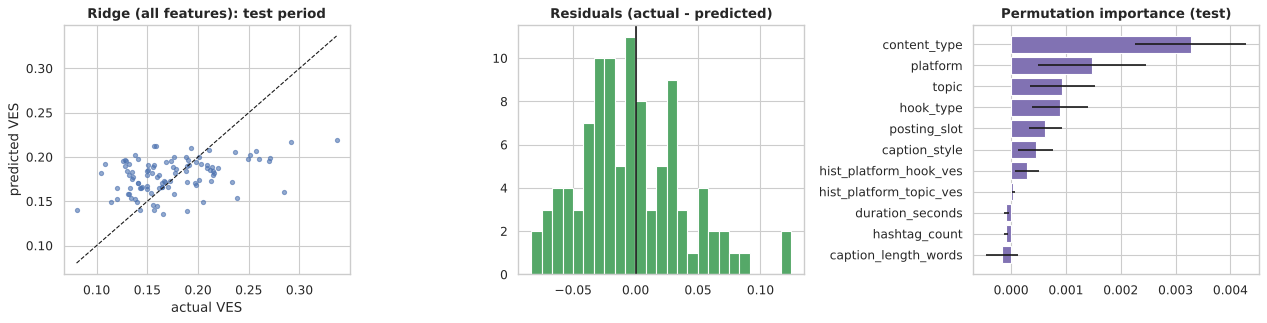

In [ ]:
best_model = candidates[best_name].fit(train[FEATURES], train[TARGET])      # trained on train only for honest test evaluation
test_pred = best_model.predict(test[FEATURES])
resid = test[TARGET].to_numpy() - test_pred
band = float(np.quantile(np.abs(resid), .80))                                # empirical 80% absolute-error band from the held-out test period
pi = permutation_importance(best_model, test[FEATURES], test[TARGET], n_repeats=15, random_state=SEED, scoring='neg_mean_absolute_error')
importance = pd.DataFrame({'feature': FEATURES, 'importance (MAE increase)': pi.importances_mean, 'std': pi.importances_std}).sort_values('importance (MAE increase)', ascending=False)
display(importance.round(5))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].scatter(test[TARGET], test_pred, s=14, alpha=.6); lim = [min(test[TARGET].min(), test_pred.min()), max(test[TARGET].max(), test_pred.max())]
ax[0].plot(lim, lim, 'k--', lw=1); ax[0].set_xlabel('actual VES'); ax[0].set_ylabel('predicted VES'); ax[0].set_title(f'{best_name}: test period')
ax[1].hist(resid, bins=25, color='#55a868'); ax[1].axvline(0, color='k'); ax[1].set_title('Residuals (actual - predicted)')
imp = importance.iloc[::-1]; ax[2].barh(imp['feature'], imp['importance (MAE increase)'], xerr=imp['std'], color='#8172b3'); ax[2].set_title('Permutation importance (test)')
plt.tight_layout(); plt.show()
print(f'80% absolute-error band from the test period: +/-{band:.4f} VES')

### 14.1 Generating recommendations
1. Refit the selected model on **all** posts (after evaluation).
2. Score every feasible combination of platform × topic × format × duration × hook × caption × posting slot (the *candidate grid*), using historical-performance features as of the data cut-off.
3. Express each score as a within-platform z-score so Instagram and YouTube candidates are comparable, attach the empirical error band and the number of historical posts supporting the platform×topic and platform×hook choice.
4. Build a 7-day plan: highest-scoring candidates, at most one post per topic, platforms alternated.

In [ ]:
final_model = candidates[best_name].fit(model_df[FEATURES], model_df[TARGET])
joblib.dump({'model': final_model, 'features': FEATURES, 'target': TARGET, 'band80': band, 'trained_through': str(model_df['publish_date'].max()),
             'data_mode': DATA_MODE}, DIRS['models'] / 'engagement_predictor.joblib')

DURATIONS = {'Short Video': [20, 45, 75], 'Long Video': [240, 480, 780], 'Carousel': [0], 'Image': [0]}
cutoff = END
hist_pt = model_df[model_df['publish_date'] <= cutoff - pd.Timedelta(hours=72)].groupby(['platform', 'topic'])['ves_core'].mean().rename('hist_platform_topic_ves')
hist_ph = model_df[model_df['publish_date'] <= cutoff - pd.Timedelta(hours=72)].groupby(['platform', 'hook_type'])['ves_core'].mean().rename('hist_platform_hook_ves')
n_pt = model_df.groupby(['platform', 'topic']).size().rename('support_platform_topic')
n_ph = model_df.groupby(['platform', 'hook_type']).size().rename('support_platform_hook')

grid = pd.DataFrame([(p, f, d, t, h, c, s) for p in PLATFORMS for f in FORMATS[p] for d in DURATIONS[f] for t in TOPICS for h in HOOKS for c in CAPTIONS for s in SLOTS],
                    columns=['platform', 'content_type_name', 'duration_seconds', 'topic', 'hook_type', 'caption_style', 'posting_slot']).rename(columns={'content_type_name': 'content_type'})
grid['caption_length_words'] = model_df['caption_length_words'].median(); grid['hashtag_count'] = model_df['hashtag_count'].median()
grid = grid.join(hist_pt, on=['platform', 'topic']).join(hist_ph, on=['platform', 'hook_type']).join(n_pt, on=['platform', 'topic']).join(n_ph, on=['platform', 'hook_type'])
grid['predicted_ves'] = final_model.predict(grid[FEATURES])
stat_ = model_df.groupby('platform')['ves_core'].agg(['mean', 'std'])
grid['predicted_ves_z'] = (grid['predicted_ves'] - grid['platform'].map(stat_['mean'])) / grid['platform'].map(stat_['std'])
grid['pred_low'], grid['pred_high'] = grid['predicted_ves'] - band, grid['predicted_ves'] + band
grid['data_basis'] = DATA_MODE
recs = grid.sort_values('predicted_ves_z', ascending=False).reset_index(drop=True)
recs.insert(0, 'rank', np.arange(1, len(recs) + 1))
print(f'{len(recs)} candidate strategies scored.')
show = ['rank', 'platform', 'topic', 'content_type', 'duration_seconds', 'hook_type', 'caption_style', 'posting_slot', 'predicted_ves', 'predicted_ves_z', 'support_platform_topic']
display(recs[show].head(10).round(4))

def weekly_plan(recs, start, per_topic=1, n_days=7):
    plan, used_topics, last_platform = [], {}, None
    for r in recs.itertuples():
        if used_topics.get(r.topic, 0) >= per_topic or r.platform == last_platform:
            continue
        plan.append({'date': (start + pd.Timedelta(days=len(plan))).date(), 'platform': r.platform, 'topic': r.topic, 'content_type': r.content_type,
                     'duration_seconds': r.duration_seconds, 'hook_type': r.hook_type, 'caption_style': r.caption_style, 'posting_slot': r.posting_slot,
                     'predicted_ves_z': r.predicted_ves_z, 'pred_low': r.pred_low, 'pred_high': r.pred_high})
        used_topics[r.topic] = used_topics.get(r.topic, 0) + 1; last_platform = r.platform
        if len(plan) == n_days:
            break
    return pd.DataFrame(plan)

weekly = weekly_plan(recs, END.normalize() + pd.Timedelta(days=1))
display(weekly.round(4))

7040 candidate strategies scored.


,rank,platform,topic,content_type,duration_seconds,hook_type,caption_style,posting_slot,predicted_ves,predicted_ves_z,support_platform_topic
0,1,YouTube,Overthinking,Short Video,20,Personal Story,Storytelling,Evening,0.2110,1.2790,27
1,2,YouTube,Overthinking,Short Video,45,Personal Story,Storytelling,Evening,0.2109,1.2754,27
2,3,YouTube,Overthinking,Short Video,75,Personal Story,Storytelling,Evening,0.2107,1.2711,27
3,4,YouTube,Overthinking,Short Video,20,Visual Hook,Storytelling,Evening,0.2075,1.1799,27
4,5,YouTube,Overthinking,Short Video,20,Question,Storytelling,Evening,0.2074,1.1768,27
5,6,YouTube,Overthinking,Short Video,45,Visual Hook,Storytelling,Evening,0.2074,1.1763,27
6,7,YouTube,Overthinking,Short Video,45,Question,Storytelling,Evening,0.2073,1.1732,27
7,8,YouTube,Overthinking,Short Video,75,Visual Hook,Storytelling,Evening,0.2072,1.1720,27
8,9,YouTube,Overthinking,Short Video,75,Question,Storytelling,Evening,0.2071,1.1689,27
9,10,YouTube,Overthinking,Short Video,20,Personal Story,Question-based,Evening,0.2067,1.1572,27


,date,platform,topic,content_type,duration_seconds,hook_type,caption_style,posting_slot,predicted_ves_z,pred_low,pred_high
0,2026-11-01,YouTube,Overthinking,Short Video,20,Personal Story,Storytelling,Evening,1.2790,0.1565,0.2656
1,2026-11-02,Instagram,Loneliness,Short Video,20,Personal Story,Storytelling,Evening,0.7363,0.1636,0.2727
2,2026-11-03,YouTube,Life Experiences,Short Video,20,Visual Hook,Storytelling,Evening,0.7063,0.1361,0.2451
3,2026-11-04,Instagram,Social Anxiety,Short Video,20,Personal Story,Storytelling,Evening,0.5730,0.1561,0.2652
4,2026-11-05,YouTube,Dating & Relationships,Short Video,20,Personal Story,Storytelling,Evening,0.5308,0.1298,0.2389
5,2026-11-06,Instagram,Self-Respect,Short Video,20,Personal Story,Storytelling,Evening,0.5080,0.1531,0.2622
6,2026-11-07,YouTube,Self-Improvement,Short Video,20,Personal Story,Storytelling,Evening,0.4939,0.1285,0.2376


### 14.2 Sanity check against the simulator's known truth (validation of the method only)
Because the simulator's true multipliers are known, we can check whether the recommender ranks each attribute's levels in the right order. This validates the *pipeline*; on real data no such truth exists.

In [ ]:
checks = []
for col, key in [('topic', 'topic'), ('hook_type', 'hook_type'), ('caption_style', 'caption_style'), ('posting_slot', 'posting_slot'), ('content_type', 'content_type')]:
    learned = recs.groupby(col)['predicted_ves_z'].mean()
    truth = pd.Series(TRUE_EFFECTS[key]).reindex(learned.index)
    rho = stats.spearmanr(learned, truth)[0]
    checks.append({'attribute': col, 'levels': len(learned), 'Spearman(learned vs true multiplier)': rho,
                   'learned best level': learned.idxmax(), 'true best level': truth.idxmax()})
display(pd.DataFrame(checks).round(3))
print('Limitation: recommendations come from SYNTHETIC history and a small sample; the error band shows that predictions are uncertain. '
      'Treat them as hypotheses to test with the A/B framework, not as guarantees.')

Limitation: recommendations come from SYNTHETIC history and a small sample; the error band shows that predictions are uncertain. Treat them as hypotheses to test with the A/B framework, not as guarantees.


,attribute,levels,Spearman(learned vs true multiplier),learned best level,true best level
0,topic,10,0.888,Overthinking,Overthinking
1,hook_type,4,0.800,Personal Story,Visual Hook
2,caption_style,4,1.000,Storytelling,Storytelling
3,posting_slot,4,0.949,Evening,Evening
4,content_type,4,1.000,Short Video,Short Video


## 15. Module 7 — Trend Forecasting
**Objective:** spot rising "relatable struggles" early and forecast them.

Two different tasks are deliberately kept separate:
* **Trend *detection*** describes the *past*: momentum (recent 14 days vs the 14 days before) and a regression slope over the last 28 days.
* **Forecasting** predicts the *future*: the mean trend score of the **next 7 days**, evaluated with **walk-forward (rolling-origin) validation** where each forecast uses only data available at its origin (no look-ahead). Baselines first: naive last-week mean → simple exponential smoothing → 28-day linear trend. Metrics: MAE, RMSE, sMAPE and directional accuracy.

**Temporal aggregation.** Daily scores are the base series; missing days are forward-filled for at most 3 days (never back-filled or interpolated from the future); weekly means (weeks ending Sunday) are used for charts.
**External data.** The default series are simulated. `load_external_trends` accepts a CSV export (e.g. Google Trends) in the project schema; no external API is connected.

In [ ]:
def load_external_trends(path, data_source='MANUAL_ENTRY'):
    """Optional: load real keyword/hashtag series (columns term, observation_date, trend_score). Not connected to any API."""
    return clean_trends(read_validated_csv(path, 'trends', data_source), IssueLog())

trend_wide = trends.pivot(index='observation_date', columns='term', values='trend_score').asfreq('D').ffill(limit=3)
weekly_long = (trend_wide.resample('W-SUN').mean().reset_index().melt(id_vars='observation_date', var_name='term', value_name='weekly_mean_score')
               .rename(columns={'observation_date': 'week_ending'}))
print(f'{trend_wide.shape[1]} terms x {trend_wide.shape[0]} days ({trend_wide.index.min():%Y-%m-%d} to {trend_wide.index.max():%Y-%m-%d}); missing after ffill: {int(trend_wide.isna().sum().sum())}')

def trend_metrics(series, window=14, slope_window=28):
    """Detection statistics computed ONLY from the supplied (historical) series."""
    s = series.dropna(); end = s.index.max()
    recent = s[s.index > end - pd.Timedelta(days=window)]
    prior = s[(s.index <= end - pd.Timedelta(days=window)) & (s.index > end - pd.Timedelta(days=2 * window))]
    mom = (recent.mean() - prior.mean()) / prior.mean() * 100 if len(prior) and prior.mean() > 0 else np.nan
    last = s[s.index > end - pd.Timedelta(days=slope_window)]
    lr = stats.linregress(np.arange(len(last)), last.to_numpy())
    cls = 'Rising' if (mom > 5 and lr.slope > 0 and lr.pvalue < .05) else 'Declining' if (mom < -5 and lr.slope < 0 and lr.pvalue < .05) else 'Stable'
    return {'last14_mean': recent.mean(), 'prior14_mean': prior.mean(), 'momentum_pct': mom, 'slope_per_day': lr.slope, 'slope_p': lr.pvalue, 'trend_class': cls}

def detect_trends(wide, as_of=None):
    w = wide if as_of is None else wide.loc[:as_of]
    return pd.DataFrame({t: trend_metrics(w[t]) for t in w.columns}).T.rename_axis('term').reset_index()

trend_summary = detect_trends(trend_wide)
trend_summary['linked_topic'] = trend_summary['term'].map(TERM_TO_TOPIC)
display(trend_summary.sort_values('momentum_pct', ascending=False).round(3))
print('Note: the slope p-values are an unadjusted screening heuristic over 10 terms, not confirmatory tests.')

10 terms x 120 days (2026-07-04 to 2026-10-31); missing after ffill: 0
Note: the slope p-values are an unadjusted screening heuristic over 10 terms, not confirmatory tests.


,term,last14_mean,prior14_mean,momentum_pct,slope_per_day,slope_p,trend_class,linked_topic
4,dating burnout,42.18,35.862143,17.617065,0.378295,0.000823,Rising,Dating & Relationships
9,social anxiety,49.275714,43.607857,12.99733,0.446357,0.00036,Rising,Social Anxiety
3,#socialbattery,40.828571,36.347143,12.329521,0.289787,0.033313,Rising,Social Anxiety
0,#friendbreakup,41.595,37.44,11.097756,0.202241,0.063087,Stable,Friendship
7,overthinking,48.057857,46.13,4.179183,0.309899,0.017469,Stable,Overthinking
2,#peoplepleaser,41.216429,40.028571,2.967523,0.129319,0.270886,Stable,Self-Improvement
5,loneliness,46.247857,45.116429,2.507797,-0.086327,0.45484,Stable,Loneliness
8,self respect,38.790714,38.512857,0.721466,0.029209,0.727139,Stable,Self-Respect
6,mental toughness,40.77,42.943571,-5.061459,-0.044568,0.757907,Stable,Mental Toughness
1,#impostersyndrome,31.342857,36.182143,-13.37479,-0.211738,0.032972,Declining,Personal Growth


### 15.1 Forecasting models and walk-forward evaluation

In [ ]:
HORIZON = 7
def fc_naive(h):  return float(h.iloc[-HORIZON:].mean())
def fc_ses(h, alpha=.3):
    level = h.iloc[0]
    for v in h.iloc[1:]:
        level = alpha * v + (1 - alpha) * level
    return float(level)
def fc_linear(h, window=28):
    y = h.iloc[-window:].to_numpy(); x = np.arange(window)
    slope, intercept = np.polyfit(x, y, 1)
    return float(np.mean(intercept + slope * np.arange(window, window + HORIZON)))
FORECASTERS = {'Naive (last 7-day mean)': fc_naive, 'Exponential smoothing (alpha=.3)': fc_ses, 'Linear trend (28d)': fc_linear}

def walk_forward(wide, min_history=56, step=7):
    rows = []
    for term in wide.columns:
        s = wide[term].dropna()
        for o in range(min_history, len(s) - HORIZON + 1, step):
            hist = s.iloc[:o]                                  # only data before the origin
            actual = s.iloc[o:o + HORIZON].mean()
            for name, f in FORECASTERS.items():
                rows.append({'term': term, 'origin': s.index[o - 1], 'model': name, 'forecast': f(hist), 'actual': actual, 'last7': fc_naive(hist)})
    return pd.DataFrame(rows)

fc_eval_rows = walk_forward(trend_wide)
def forecast_scores(df):
    e = df['actual'] - df['forecast']
    move = np.sign(df['forecast'] - df['last7']); real = np.sign(df['actual'] - df['last7'])
    return pd.Series({'n_forecasts': len(df), 'MAE': e.abs().mean(), 'RMSE': np.sqrt((e ** 2).mean()),
                      'sMAPE_%': (200 * e.abs() / (df['actual'].abs() + df['forecast'].abs())).mean(),
                      'directional_acc': (move == real)[move != 0].mean() if (move != 0).any() else np.nan})
fc_eval = fc_eval_rows.groupby('model')[['forecast', 'actual', 'last7']].apply(forecast_scores).reset_index()
naive_rmse = fc_eval.loc[fc_eval['model'].str.startswith('Naive'), 'RMSE'].iloc[0]
fc_eval['RMSE_vs_naive'] = fc_eval['RMSE'] / naive_rmse
display(fc_eval.round(3))

if DATA_MODE == 'SIMULATED':                                # ground-truth trend labels exist only in the simulator
    truth = {t: ('Rising' if v[2] > 0 else 'Declining' if v[2] < 0 else 'Flat') for t, v in TREND_SPEC.items()}
    fc_eval_rows['true_pattern'] = fc_eval_rows['term'].map(truth)
    by = fc_eval_rows.groupby(['true_pattern', 'model'])[['forecast', 'actual', 'last7']].apply(forecast_scores)['RMSE'].unstack().round(3)
    print('Simulation-only breakdown: RMSE by the simulator\'s true pattern (lower is better)')
    display(by)

Simulation-only breakdown: RMSE by the simulator's true pattern (lower is better)


,model,n_forecasts,MAE,RMSE,sMAPE_%,directional_acc,RMSE_vs_naive
0,Exponential smoothing (alpha=.3),90.0,3.217,4.000,8.186,0.567,0.967
1,Linear trend (28d),90.0,3.688,4.517,9.190,0.556,1.092
2,Naive (last 7-day mean),90.0,3.169,4.135,8.026,NaN,1.000


model,Exponential smoothing (alpha=.3),Linear trend (28d),Naive (last 7-day mean)
true_pattern,,,
Declining,3.641,3.875,3.335
Flat,4.420,5.136,4.759
Rising,3.455,3.746,3.441


### 15.2 Does a "Rising" flag really precede an increase? (detection back-test)
At each weekly origin the detector sees only past data; the outcome is whether the *next* 7-day mean exceeded the last 7-day mean. A useful flag must beat the base rate.

Base rate (any week followed by an increase): 0.500
Forecast model with lowest walk-forward RMSE: Exponential smoothing (alpha=.3)


,n_flags,share_followed_by_increase
flag,,
Declining,9,0.778
Rising,12,0.333
Stable,69,0.493


,term,last7_mean,forecast_next7_mean,expected_change,trend_class,momentum_pct,linked_topic,forecast_model,forecast_from,forecast_to,data_basis
7,overthinking,48.533,52.221,3.688,Stable,4.179183,Overthinking,Exponential smoothing (alpha=.3),2026-11-01,2026-11-07,SIMULATED
2,#peoplepleaser,42.113,43.932,1.820,Stable,2.967523,Self-Improvement,Exponential smoothing (alpha=.3),2026-11-01,2026-11-07,SIMULATED
3,#socialbattery,40.459,42.083,1.625,Rising,12.329521,Social Anxiety,Exponential smoothing (alpha=.3),2026-11-01,2026-11-07,SIMULATED
6,mental toughness,43.513,43.890,0.377,Stable,-5.061459,Mental Toughness,Exponential smoothing (alpha=.3),2026-11-01,2026-11-07,SIMULATED
4,dating burnout,44.499,44.790,0.292,Rising,17.617065,Dating & Relationships,Exponential smoothing (alpha=.3),2026-11-01,2026-11-07,SIMULATED
1,#impostersyndrome,31.744,31.226,-0.518,Declining,-13.37479,Personal Growth,Exponential smoothing (alpha=.3),2026-11-01,2026-11-07,SIMULATED
0,#friendbreakup,40.727,40.133,-0.594,Stable,11.097756,Friendship,Exponential smoothing (alpha=.3),2026-11-01,2026-11-07,SIMULATED
5,loneliness,44.240,43.404,-0.836,Stable,2.507797,Loneliness,Exponential smoothing (alpha=.3),2026-11-01,2026-11-07,SIMULATED
8,self respect,39.629,38.714,-0.914,Stable,0.721466,Self-Respect,Exponential smoothing (alpha=.3),2026-11-01,2026-11-07,SIMULATED
9,social anxiety,51.553,49.461,-2.092,Rising,12.99733,Social Anxiety,Exponential smoothing (alpha=.3),2026-11-01,2026-11-07,SIMULATED


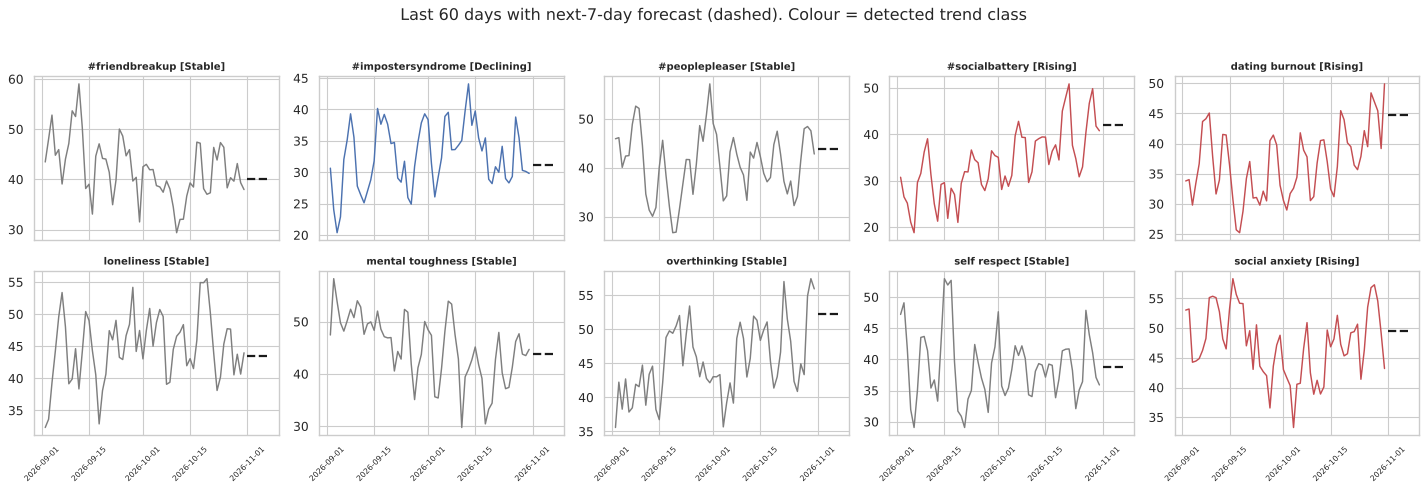

In [ ]:
bt = []
for term in trend_wide.columns:
    s = trend_wide[term].dropna()
    for o in range(56, len(s) - HORIZON + 1, 7):
        m = trend_metrics(s.iloc[:o])
        bt.append({'term': term, 'flag': m['trend_class'], 'up_next_week': s.iloc[o:o + HORIZON].mean() > fc_naive(s.iloc[:o])})
bt = pd.DataFrame(bt)
bt_tab = bt.groupby('flag')['up_next_week'].agg(['size', 'mean']).rename(columns={'size': 'n_flags', 'mean': 'share_followed_by_increase'})
display(bt_tab.round(3))
print(f'Base rate (any week followed by an increase): {bt["up_next_week"].mean():.3f}')

best_fc = fc_eval.loc[fc_eval['RMSE'].idxmin(), 'model']
as_of = trend_wide.index.max()
trend_forecast = pd.DataFrame({'term': trend_wide.columns,
                               'last7_mean': [fc_naive(trend_wide[t].dropna()) for t in trend_wide.columns],
                               'forecast_next7_mean': [FORECASTERS[best_fc](trend_wide[t].dropna()) for t in trend_wide.columns]})
trend_forecast['expected_change'] = trend_forecast['forecast_next7_mean'] - trend_forecast['last7_mean']
trend_forecast = trend_forecast.merge(trend_summary[['term', 'trend_class', 'momentum_pct', 'linked_topic']], on='term')
trend_forecast['forecast_model'] = best_fc
trend_forecast['forecast_from'] = (as_of + pd.Timedelta(days=1)).date(); trend_forecast['forecast_to'] = (as_of + pd.Timedelta(days=HORIZON)).date()
trend_forecast['data_basis'] = DATA_MODE
print(f'Forecast model with lowest walk-forward RMSE: {best_fc}')
display(trend_forecast.sort_values('expected_change', ascending=False).round(3))

fig, axes = plt.subplots(2, 5, figsize=(18, 6), sharex=True)
colors = {'Rising': '#c44e52', 'Declining': '#4c72b0', 'Stable': '#7f7f7f'}
for ax, term in zip(axes.ravel(), trend_wide.columns):
    s = trend_wide[term].iloc[-60:]; cls = trend_summary.set_index('term').loc[term, 'trend_class']
    ax.plot(s.index, s.values, color=colors[cls], lw=1.3)
    f = trend_forecast.set_index('term').loc[term, 'forecast_next7_mean']
    ax.hlines(f, as_of + pd.Timedelta(days=1), as_of + pd.Timedelta(days=HORIZON), color='k', ls='--', lw=2)
    ax.set_title(f'{term} [{cls}]', fontsize=9); ax.tick_params(axis='x', labelrotation=45, labelsize=7)
fig.suptitle('Last 60 days with next-7-day forecast (dashed). Colour = detected trend class', y=1.02); plt.tight_layout(); plt.show()

**Reading Module 7.** Detection classes describe what already happened; the forecast table is the only forward-looking output. If no forecaster clearly beats the naive baseline in `RMSE_vs_naive`, a trend-following model adds little and the baseline should be preferred — the table above reports this plainly. Detection precision is judged against the base rate, not against 50%.

## 16. Module 6 — Growth Visualization
Every chart below is computed from the actual tables (no random values). `apply_filters` implements the **platform, topic, content-format and date filters**; the same logic powers the exported Streamlit app, which adds interactive widgets. Panels: engagement trend, topic performance, sentiment distribution, relatability, **save-to-share** (overall and over time since publishing — the moments users felt most understood) and topic-vs-follower-growth.

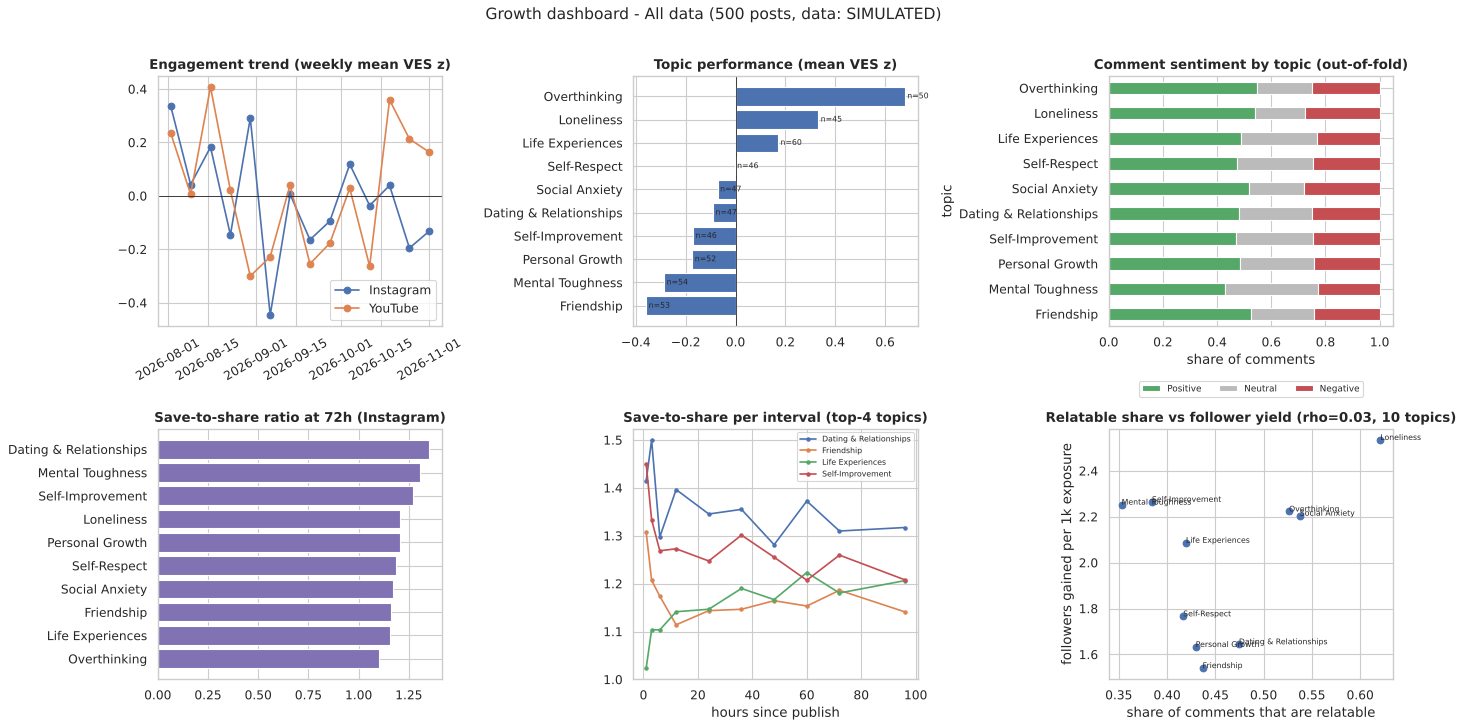

In [ ]:
def apply_filters(df, platforms=None, topics=None, content_types=None, date_range=None, date_col='publish_date'):
    m = pd.Series(True, index=df.index)
    if platforms:      m &= df['platform'].isin(platforms)
    if topics:         m &= df['topic'].isin(topics)
    if content_types:  m &= df['content_type'].isin(content_types)
    if date_range:     m &= df[date_col].between(pd.Timestamp(date_range[0]), pd.Timestamp(date_range[1]))
    return df[m]

def save_share_curve(snaps, content_view):
    ig = content_view.loc[content_view['platform'] == 'Instagram', ['content_id', 'topic']]
    s = snaps.merge(ig, on='content_id')
    agg = s.groupby(['topic', 'hours_since_publish'])[['saves', 'shares']].sum().reset_index().sort_values(['topic', 'hours_since_publish'])
    agg['cumulative_save_to_share'] = safe_div(agg['saves'], agg['shares'])
    agg['interval_saves'] = agg['saves'] - agg.groupby('topic')['saves'].shift(1).fillna(0)
    agg['interval_shares'] = agg['shares'] - agg.groupby('topic')['shares'].shift(1).fillna(0)
    agg['interval_save_to_share'] = safe_div(agg['interval_saves'], agg['interval_shares'])
    return agg

def weekly_engagement(view):
    w = view.assign(week=view['publish_date'].dt.to_period('W-SUN').dt.end_time.dt.normalize())
    return w.groupby(['week', 'platform']).agg(posts=('content_id', 'size'), mean_ves_z=('ves_core_z', 'mean'), mean_share_rate=('share_rate', 'mean')).reset_index()

def render_dashboard(filters=None, label='All data', save_as=None):
    f = filters or {}
    view = apply_filters(analysis, **f); cview = apply_filters(comments_scored, **f); cont = apply_filters(content, **f)
    if view.empty:
        print('No posts match these filters.'); return
    fig, ax = plt.subplots(2, 3, figsize=(18, 9))
    we = weekly_engagement(view)
    for p, g in we.groupby('platform'):
        ax[0, 0].plot(g['week'], g['mean_ves_z'], marker='o', label=p)
    ax[0, 0].axhline(0, color='k', lw=.7); ax[0, 0].set_title('Engagement trend (weekly mean VES z)'); ax[0, 0].legend(); ax[0, 0].tick_params(axis='x', labelrotation=30)
    tp = view.groupby('topic')['ves_core_z'].agg(['mean', 'size']).sort_values('mean')
    ax[0, 1].barh(tp.index, tp['mean'], color='#4c72b0'); ax[0, 1].axvline(0, color='k', lw=.7); ax[0, 1].set_title('Topic performance (mean VES z)')
    for i, (m, n) in enumerate(zip(tp['mean'], tp['size'])): ax[0, 1].text(m, i, f' n={n}', va='center', fontsize=7)
    sent = pd.crosstab(cview['topic'], cview['pred_sentiment'], normalize='index').reindex(columns=['Positive', 'Neutral', 'Negative'], fill_value=0)
    sent.loc[tp.index.intersection(sent.index)].plot.barh(stacked=True, ax=ax[0, 2], color=['#55a868', '#bbbbbb', '#c44e52'])
    ax[0, 2].set_title('Comment sentiment by topic (out-of-fold)'); ax[0, 2].set_xlabel('share of comments'); ax[0, 2].legend(loc='upper center', bbox_to_anchor=(.5, -.2), ncol=3, fontsize=8)
    ig_view = view[view['platform'] == 'Instagram']
    if len(ig_view):
        ss = (ig_view.groupby('topic')[['saves', 'shares']].sum().assign(r=lambda d: safe_div(d['saves'], d['shares'])).sort_values('r'))
        ax[1, 0].barh(ss.index, ss['r'], color='#8172b3'); ax[1, 0].set_title('Save-to-share ratio at 72h (Instagram)')
    else:
        ax[1, 0].text(.5, .5, 'No Instagram posts in filter', ha='center'); ax[1, 0].set_title('Save-to-share (Instagram)')
    curve = save_share_curve(snapshots, cont)
    if len(curve):
        top = curve.groupby('topic')['saves'].sum().nlargest(4).index
        for t, g in curve[curve['topic'].isin(top)].groupby('topic'):
            ax[1, 1].plot(g['hours_since_publish'], g['interval_save_to_share'], marker='o', ms=3, label=t)
        ax[1, 1].set_title('Save-to-share per interval (top-4 topics)'); ax[1, 1].set_xlabel('hours since publish'); ax[1, 1].legend(fontsize=7)
    rel = cview.groupby('topic')['is_relatable'].mean().rename('relatable_share')
    sc = view.groupby('topic')['followers_per_1k_exposure'].mean().to_frame().join(rel).dropna()
    ax[1, 2].scatter(sc['relatable_share'], sc['followers_per_1k_exposure'])
    for t, r in sc.iterrows(): ax[1, 2].annotate(t, (r['relatable_share'], r['followers_per_1k_exposure']), fontsize=7)
    rho = stats.spearmanr(sc['relatable_share'], sc['followers_per_1k_exposure'])[0] if len(sc) > 3 else np.nan
    ax[1, 2].set_title(f'Relatable share vs follower yield (rho={rho:.2f}, {len(sc)} topics)'); ax[1, 2].set_xlabel('share of comments that are relatable'); ax[1, 2].set_ylabel('followers gained per 1k exposure')
    fig.suptitle(f'Growth dashboard - {label} ({len(view)} posts, data: {DATA_MODE})', fontsize=14, y=1.01); plt.tight_layout()
    if save_as:
        fig.savefig(DIRS['viz'] / save_as, dpi=110, bbox_inches='tight')
    plt.show()

render_dashboard(label='All data', save_as='dashboard_all_data.png')

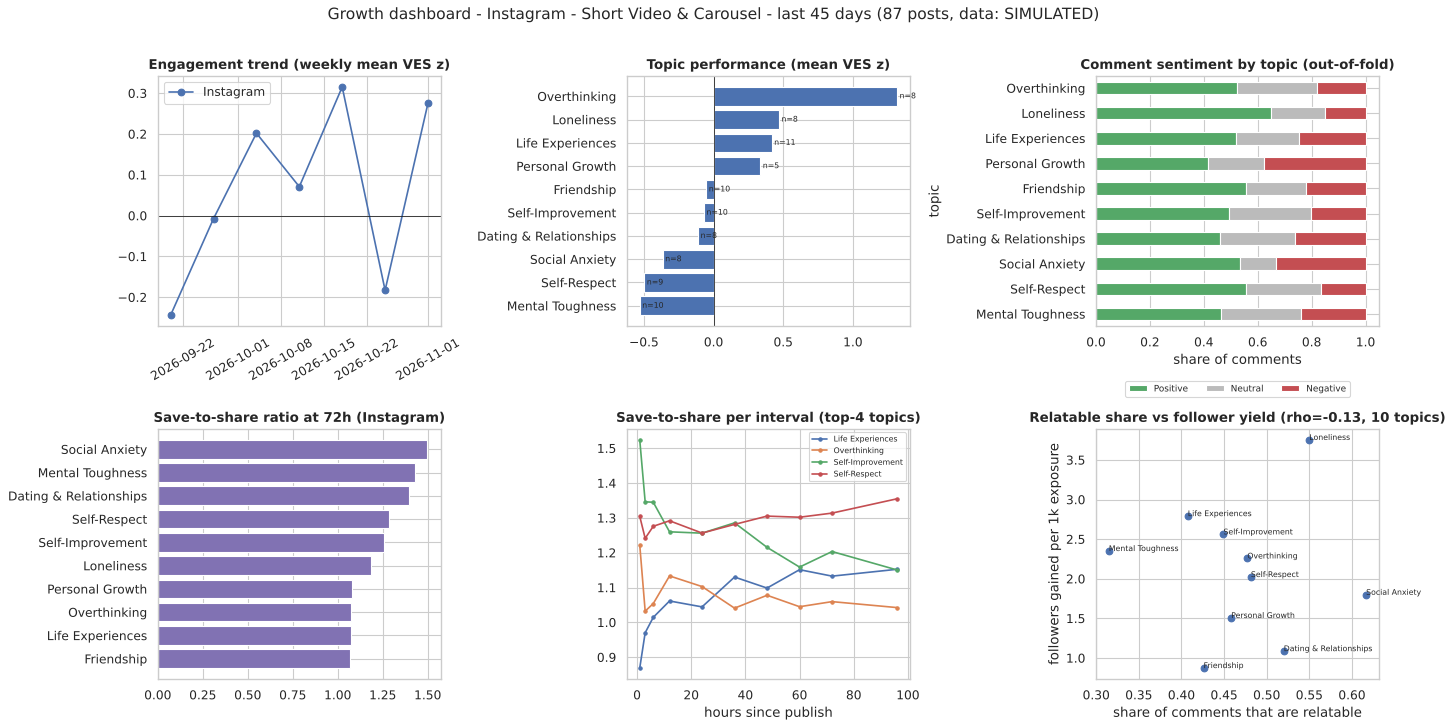

In [ ]:
last_45 = (END - pd.Timedelta(days=45), END)
render_dashboard({'platforms': ['Instagram'], 'content_types': ['Short Video', 'Carousel'], 'date_range': last_45}, label='Instagram - Short Video & Carousel - last 45 days', save_as='dashboard_instagram_filtered.png')

*Reading the dashboard.* Topic bars come from Module 2, sentiment from Module 3 (out-of-fold predictions), save-to-share from the cumulative snapshots. The topic-vs-follower scatter has only 10 points, so its Spearman value is descriptive — **correlation between topics is not causation**.

## 17. Integrated Results
All modules read from the same validated tables and feed one **topic scorecard**. The *Connection index* is a transparent heuristic: the mean of three z-scores across topics — VES z, relatable-comment share, and followers per 1k exposure (equal weights, an assumption). It is a ranking aid, not a statistical estimate.

In [ ]:
ig_ss = (analysis[analysis['platform'] == 'Instagram'].groupby('topic')[['saves', 'shares']].sum().assign(save_to_share_ig=lambda d: safe_div(d['saves'], d['shares']))[['save_to_share_ig']])
trend_by_topic = (trend_summary.sort_values('momentum_pct', ascending=False).groupby('linked_topic')
                  .agg(best_term=('term', 'first'), trend_momentum_pct=('momentum_pct', 'max'), trend_class=('trend_class', 'first')))
scorecard = (topic_perf[['topic', 'n_posts', 'mean_ves_z', 'ci_low', 'ci_high', 'mean_followers_per_1k']]
             .merge(rel_topic[['relatable_share_pred', 'n_comments']].reset_index(), on='topic')
             .merge(ig_ss.reset_index(), on='topic', how='left').merge(trend_by_topic.reset_index().rename(columns={'linked_topic': 'topic'}), on='topic', how='left'))
z = lambda s: (s - s.mean()) / s.std(ddof=1)
scorecard['connection_index'] = (z(scorecard['mean_ves_z']) + z(scorecard['relatable_share_pred']) + z(scorecard['mean_followers_per_1k'])) / 3
scorecard = scorecard.sort_values('connection_index', ascending=False).reset_index(drop=True)
scorecard.insert(0, 'rank', np.arange(1, len(scorecard) + 1)); scorecard['data_basis'] = DATA_MODE
display(scorecard.round(3))

best_adv = model_metrics.set_index('model').loc[best_name]
base_m = model_metrics.set_index('model').loc['Mean baseline']
tg = nlp_results[(nlp_results['task'].str.startswith('Relatable')) & (nlp_results['model'].str.startswith('TF-IDF'))].set_index('evaluation')
integrated_summary = pd.DataFrame([
    ('Data', 'Posts / snapshots / comments', f'{len(content)} / {len(snapshots)} / {len(comments)}', f'DATA_MODE={DATA_MODE}'),
    ('M1 Tracker', 'Validated; cumulative counters monotone', f'{mono.mean():.0%} of posts', 'validators self-tested'),
    ('M2 Virality', 'Kruskal-Wallis across topics', f'p={p_kw:.2g}, eps2={eps2:.3f}', 'simulated effects'),
    ('M3 Sentiment', 'Relatable F1 (text-grouped / template-held-out)', f"{tg.loc['text-grouped split','f1']:.2f} / {tg.loc['template-held-out split','f1']:.2f}" if 'template-held-out split' in tg.index else f"{tg.loc['text-grouped split','f1']:.2f}", 'SYNTHETIC labels - not real-world accuracy'),
    ('M4 A/B', 'Observational tests significant after Holm', f"{int(ab['significant_after_holm'].sum())} of {len(ab)}", 'association only; not causal'),
    ('M4 A/B', 'Simulated A/A type-I error', f'{type1.min():.3f}-{type1.max():.3f}', 'nominal 0.05'),
    ('M5 Recommender', f'{best_name}: test RMSE (mean baseline RMSE)', f"{best_adv['test RMSE']:.4f} ({base_m['test RMSE']:.4f})", 'chronological hold-out'),
    ('M5 Recommender', 'Test R2', f"{best_adv['test R2']:.3f}", 'synthetic data'),
    ('M7 Forecast', f'{best_fc}: RMSE relative to naive', f"{fc_eval.set_index('model').loc[best_fc, 'RMSE_vs_naive']:.2f}", 'walk-forward'),
    ('M7 Detection', "'Rising' flags followed by increase vs base rate", f"{bt_tab.loc['Rising', 'share_followed_by_increase']:.2f} vs {bt['up_next_week'].mean():.2f}" if 'Rising' in bt_tab.index else 'no Rising flags', 'back-test')],
    columns=['module', 'result', 'value', 'validity note'])
display(integrated_summary)

,rank,topic,n_posts,mean_ves_z,ci_low,ci_high,mean_followers_per_1k,relatable_share_pred,n_comments,save_to_share_ig,best_term,trend_momentum_pct,trend_class,connection_index,data_basis
0,1,Loneliness,45,0.332,0.048,0.603,2.535,0.644,298,1.206,loneliness,2.507797,Stable,1.500,SIMULATED
1,2,Overthinking,50,0.679,0.395,0.962,2.223,0.546,361,1.102,overthinking,4.179183,Stable,1.191,SIMULATED
2,3,Social Anxiety,47,-0.072,-0.331,0.187,2.205,0.570,307,1.172,social anxiety,12.99733,Rising,0.467,SIMULATED
3,4,Life Experiences,60,0.170,-0.052,0.395,2.087,0.433,441,1.157,NaN,NaN,NaN,0.090,SIMULATED
4,5,Self-Improvement,46,-0.171,-0.416,0.080,2.265,0.392,268,1.269,#peoplepleaser,2.967523,Stable,-0.255,SIMULATED
5,6,Self-Respect,46,-0.004,-0.295,0.331,1.766,0.430,228,1.185,self respect,0.721466,Stable,-0.421,SIMULATED
6,7,Dating & Relationships,47,-0.090,-0.388,0.215,1.644,0.481,293,1.349,dating burnout,17.617065,Rising,-0.438,SIMULATED
7,8,Mental Toughness,54,-0.286,-0.524,-0.064,2.253,0.353,289,1.304,mental toughness,-5.061459,Stable,-0.536,SIMULATED
8,9,Personal Growth,52,-0.173,-0.441,0.086,1.632,0.459,270,1.206,#impostersyndrome,-13.37479,Declining,-0.621,SIMULATED
9,10,Friendship,53,-0.358,-0.588,-0.103,1.541,0.441,245,1.162,#friendbreakup,11.097756,Stable,-0.978,SIMULATED


,module,result,value,validity note
0,Data,Posts / snapshots / comments,500 / 5000 / 3000,DATA_MODE=SIMULATED
1,M1 Tracker,Validated; cumulative counters monotone,100% of posts,validators self-tested
2,M2 Virality,Kruskal-Wallis across topics,"p=3.5e-06, eps2=0.067",simulated effects
3,M3 Sentiment,Relatable F1 (text-grouped / template-held-out),0.96 / 0.58,SYNTHETIC labels - not real-world accuracy
4,M4 A/B,Observational tests significant after Holm,1 of 6,association only; not causal
5,M4 A/B,Simulated A/A type-I error,0.038-0.051,nominal 0.05
6,M5 Recommender,Ridge (all features): test RMSE (mean baseline...,0.0415 (0.0450),chronological hold-out
7,M5 Recommender,Test R2,0.147,synthetic data
8,M7 Forecast,Exponential smoothing (alpha=.3): RMSE relativ...,0.97,walk-forward
9,M7 Detection,'Rising' flags followed by increase vs base rate,0.33 vs 0.50,back-test


### 17.1 Exports (consumed by the Streamlit app, SQL, and the strategy report)

In [ ]:
EXPORT_LOG = []
def export_csv(df, name, folder='processed'):
    path = DIRS[folder] / name
    df.to_csv(path, index=False)
    EXPORT_LOG.append({'file': str(path.relative_to(ROOT)), 'rows': len(df), 'columns': df.shape[1], 'sha256_12': file_sha(path)})

export_csv(content, 'content_clean.csv'); export_csv(snapshots, 'snapshots_clean.csv')
export_csv(analysis, 'content_analysis_72h.csv'); export_csv(comments_scored, 'comments_scored.csv')
export_csv(trends, 'trend_data.csv'); export_csv(dq_report, 'data_quality_report.csv')
export_csv(topic_perf, 'topic_performance.csv'); export_csv(rel_topic.reset_index(), 'relatability_by_topic.csv'); export_csv(scorecard, 'topic_scorecard.csv')
export_csv(nlp_results, 'nlp_model_results.csv')
export_csv(EXPERIMENTS.assign(**{'status': 'design (observational analysis + simulated RCT)'}), 'experiments.csv')
export_csv(ab[cols + ['evidence_type']], 'ab_results.csv'); export_csv(pd.DataFrame(sec_rows), 'ab_secondary_results.csv')
export_csv(plan, 'ab_power_plan.csv'); export_csv(mc, 'ab_monte_carlo.csv')
export_csv(rct[['content_id', 'variant', 'platform', 'topic', 'hook_type']].merge(rct_an[['content_id', 'ves_core_z']], on='content_id'), 'ab_simulated_rct.csv')
export_csv(model_metrics, 'model_metrics.csv'); export_csv(importance, 'feature_importance.csv')
export_csv(recs, 'recommendations.csv'); export_csv(weekly, 'weekly_plan.csv')
export_csv(trend_summary, 'trend_summary.csv'); export_csv(fc_eval, 'trend_forecast_eval.csv'); export_csv(trend_forecast, 'trend_forecast.csv'); export_csv(weekly_long, 'trend_weekly.csv')
export_csv(save_share_curve(snapshots, content), 'save_share_curve.csv')
export_csv(weekly_engagement(analysis), 'weekly_engagement.csv')
export_csv(analysis.assign(day=analysis['publish_date'].dt.normalize()).groupby('day')['followers_gained'].sum().rename('followers_gained').reset_index(), 'follower_daily.csv')
export_csv(integrated_summary, 'integrated_summary.csv', folder='reports')
display(pd.DataFrame(EXPORT_LOG))

,file,rows,columns,sha256_12
0,datasets/processed/content_clean.csv,500,13,7530e21a93f9
1,datasets/processed/snapshots_clean.csv,5000,13,d7494e66a6cb
2,datasets/processed/content_analysis_72h.csv,500,44,e2c88bd24ed9
3,datasets/processed/comments_scored.csv,3000,20,e5cff9a14fde
4,datasets/processed/trend_data.csv,1200,7,4bdb94aef2db
5,datasets/processed/data_quality_report.csv,24,4,df3b3303212e
6,datasets/processed/topic_performance.csv,10,8,8c0edcaddbe0
7,datasets/processed/relatability_by_topic.csv,10,5,9d87b8ab8212
8,datasets/processed/topic_scorecard.csv,10,15,fc3e003220d7
9,datasets/processed/nlp_model_results.csv,8,8,1cc1e3259cc5


### 17.2 Strategy report, SQL schema, requirements and the Streamlit app
The strategy report is **generated from the computed tables** (nothing typed by hand), and carries a prominent warning when the data is simulated.

In [ ]:
def md_table(df, floatfmt='{:.3f}'):
    head = '| ' + ' | '.join(map(str, df.columns)) + ' |\n|' + '---|' * len(df.columns) + '\n'
    body = ''.join('| ' + ' | '.join(floatfmt.format(v) if isinstance(v, float) else str(v) for v in r) + ' |\n' for r in df.itertuples(index=False))
    return head + body

def build_strategy_report():
    banner = ('> **WARNING - SIMULATED DATA.** Every figure below comes from a simulator, not from real Instagram/YouTube accounts. '
              'The report demonstrates the method; replace the data and re-run before acting on any number.\n\n') if DATA_MODE == 'SIMULATED' else ''
    top = scorecard.head(5)[['rank', 'topic', 'connection_index', 'mean_ves_z', 'relatable_share_pred', 'mean_followers_per_1k']]
    sig = ab[ab['significant_after_holm']][['name', 'diff', 'ci_low', 'ci_high', 'p_holm']]
    rising = trend_forecast[trend_forecast['trend_class'] == 'Rising'][['term', 'momentum_pct', 'last7_mean', 'forecast_next7_mean']]
    return (f'# Strategy Report - Data-Driven Social Engagement Initiative\n\nData basis: **{DATA_MODE}** | {len(content)} posts | {len(comments)} comments | cut-off {END:%Y-%m-%d}\n\n{banner}'
            f'## 1. Topics that drive the most connection\nRanked by the connection index (mean of z-scores of VES, relatable-comment share, followers per 1k exposure).\n\n{md_table(top)}\n'
            f'Kruskal-Wallis across topics: p = {p_kw:.4f} (epsilon^2 = {eps2:.3f}). Topic differences are {"statistically detectable" if p_kw < .05 else "not statistically detectable"} at 5%.\n\n'
            f'## 2. Format / hook / timing evidence (observational, not causal)\n'
            + (f'Differences surviving Holm correction:\n\n{md_table(sig)}\n' if len(sig) else 'No comparison survived Holm correction.\n')
            + f'\nComparisons with CIs spanning zero are inconclusive (see `mde_d_at_observed_n` in `ab_results.csv`).\n\n'
            f'## 3. Recommended plan for the coming week\n{md_table(weekly[["date", "platform", "topic", "content_type", "duration_seconds", "hook_type", "caption_style", "posting_slot"]])}\n'
            f'Model: {best_name}; test RMSE {best_adv["test RMSE"]:.4f} vs mean baseline {base_m["test RMSE"]:.4f}; 80% error band +/-{band:.3f} VES. Treat as hypotheses to A/B test.\n\n'
            f'## 4. Emerging trends\n' + (md_table(rising) if len(rising) else 'No term is currently classified as Rising.\n')
            + f'\nForecast model: {best_fc} (walk-forward RMSE relative to naive = {fc_eval.set_index("model").loc[best_fc, "RMSE_vs_naive"]:.2f}).\n\n'
            f'## 5. Limitations\n- Data are simulated; comment labels are synthetic rule labels, not human annotations.\n- A/B comparisons on history are observational.\n- Forecasts cover 7 days; no external API is connected.\n')

(DIRS['reports'] / 'strategy_report.md').write_text(build_strategy_report(), encoding='utf-8')

SCHEMA_SQL = '''-- Portable (SQLite/PostgreSQL/MySQL-compatible types). Loaded and checked on SQLite in the notebook test suite.
CREATE TABLE IF NOT EXISTS content (
  content_id INTEGER PRIMARY KEY, external_content_id VARCHAR(50), platform VARCHAR(20) NOT NULL, topic VARCHAR(60) NOT NULL,
  content_type VARCHAR(30) NOT NULL, hook_type VARCHAR(30), caption_style VARCHAR(30), duration_seconds INTEGER,
  caption_length_words INTEGER, hashtag_count INTEGER, publish_date TIMESTAMP NOT NULL, posting_slot VARCHAR(15), data_source VARCHAR(20) NOT NULL);
CREATE TABLE IF NOT EXISTS snapshots (
  metric_id INTEGER PRIMARY KEY, content_id INTEGER NOT NULL REFERENCES content(content_id), snapshot_date TIMESTAMP NOT NULL,
  hours_since_publish INTEGER NOT NULL, views INTEGER, reach REAL, likes INTEGER, comments INTEGER, shares INTEGER, saves REAL,
  retention_rate REAL, followers_gained INTEGER, data_source VARCHAR(20) NOT NULL);
CREATE TABLE IF NOT EXISTS comments (
  comment_id INTEGER PRIMARY KEY, content_id INTEGER NOT NULL REFERENCES content(content_id), comment_text TEXT NOT NULL,
  comment_date TIMESTAMP, sentiment VARCHAR(15), relatability_label VARCHAR(15), label_source VARCHAR(30), data_source VARCHAR(20) NOT NULL);
CREATE TABLE IF NOT EXISTS trends (
  trend_id INTEGER PRIMARY KEY, term VARCHAR(60) NOT NULL, term_type VARCHAR(15), observation_date DATE NOT NULL, trend_score REAL, platform VARCHAR(10), data_source VARCHAR(20) NOT NULL);
'''
(DIRS['sql'] / 'schema.sql').write_text(SCHEMA_SQL, encoding='utf-8')
(ROOT / 'requirements.txt').write_text('\n'.join(f'{n}>={v}' for n, v in [('pandas', pd.__version__.split('+')[0]), ('numpy', np.__version__), ('scipy', __import__('scipy').__version__),
    ('scikit-learn', sklearn.__version__), ('matplotlib', __import__('matplotlib').__version__), ('seaborn', sns.__version__), ('joblib', joblib.__version__), ('streamlit', '1.30')]) + '\n')
print('Wrote strategy_report.md, sql/schema.sql, requirements.txt')

Wrote strategy_report.md, sql/schema.sql, requirements.txt


In [ ]:
APP_CODE = r'''"""Streamlit dashboard - reads ONLY the CSV/JSON files exported by the notebook. Run:  streamlit run dashboard/app.py"""
import json
from pathlib import Path
import pandas as pd
import streamlit as st

ROOT = Path(__file__).resolve().parent.parent
PROC = ROOT / "datasets" / "processed"
st.set_page_config(page_title="Social Engagement Dashboard", layout="wide")

@st.cache_data
def load(name, dates=()):
    path = PROC / name
    if not path.exists():
        raise FileNotFoundError(f"{name} not found in {PROC}. Run the notebook first.")
    return pd.read_csv(path, parse_dates=list(dates))

manifest_path = ROOT / "reports" / "project_manifest.json"
mode = json.loads(manifest_path.read_text())["data_mode"] if manifest_path.exists() else "UNKNOWN"
st.title("Data-Driven Social Engagement Initiative")
if mode != "REAL":
    st.warning(f"Data mode: {mode}. Figures are NOT real social-media results.")

posts = load("content_analysis_72h.csv", ["publish_date"])
comments = load("comments_scored.csv", ["publish_date", "comment_date"])
curve = load("save_share_curve.csv")
recs = load("recommendations.csv")
weekly_plan = load("weekly_plan.csv")
trend_data = load("trend_data.csv", ["observation_date"])
forecast = load("trend_forecast.csv")
trend_sum = load("trend_summary.csv")
scorecard = load("topic_scorecard.csv")
metrics = load("model_metrics.csv")
ab = load("ab_results.csv")

st.sidebar.header("Filters")
platforms = st.sidebar.multiselect("Platform", sorted(posts["platform"].unique()), default=sorted(posts["platform"].unique()))
topics = st.sidebar.multiselect("Topic", sorted(posts["topic"].unique()), default=sorted(posts["topic"].unique()))
formats = st.sidebar.multiselect("Content format", sorted(posts["content_type"].unique()), default=sorted(posts["content_type"].unique()))
dmin, dmax = posts["publish_date"].min().date(), posts["publish_date"].max().date()
span = st.sidebar.date_input("Publish date range", (dmin, dmax))
start, end = (span[0], span[1]) if len(span) == 2 else (dmin, dmax)

def flt(df, date_col="publish_date"):
    m = df["platform"].isin(platforms) & df["topic"].isin(topics) & df["content_type"].isin(formats)
    return df[m & df[date_col].dt.date.between(start, end)]

v, c = flt(posts), flt(comments)
if v.empty:
    st.error("No posts match the filters.")
    st.stop()

tabs = st.tabs(["Overview", "Topics", "Sentiment", "Save-to-Share", "Recommendations", "Trends", "Models and A/B"])
with tabs[0]:
    a, b, d = st.columns(3)
    a.metric("Posts", len(v)); b.metric("Mean VES z", f"{v['ves_core_z'].mean():.2f}"); d.metric("Followers gained", int(v["followers_gained"].sum()))
    wk = v.assign(week=v["publish_date"].dt.to_period("W-SUN").dt.end_time.dt.normalize()).groupby(["week", "platform"])["ves_core_z"].mean().unstack()
    st.subheader("Weekly engagement (VES z-score)"); st.line_chart(wk)
with tabs[1]:
    t = v.groupby("topic").agg(posts=("content_id", "size"), mean_ves_z=("ves_core_z", "mean"), followers_per_1k=("followers_per_1k_exposure", "mean")).sort_values("mean_ves_z", ascending=False)
    st.bar_chart(t["mean_ves_z"]); st.dataframe(t); st.subheader("Topic scorecard (all data)"); st.dataframe(scorecard)
with tabs[2]:
    if c.empty:
        st.info("No comments for this filter.")
    else:
        st.subheader("Sentiment by topic"); st.bar_chart(pd.crosstab(c["topic"], c["pred_sentiment"], normalize="index"))
        st.subheader("Relatable-comment share by topic"); st.bar_chart(c.groupby("topic")["is_relatable"].mean())
with tabs[3]:
    ig = curve[curve["topic"].isin(topics)]
    if ig.empty:
        st.info("Save-to-share exists for Instagram only.")
    else:
        st.line_chart(ig.pivot(index="hours_since_publish", columns="topic", values="interval_save_to_share"))
with tabs[4]:
    plat = st.sidebar.selectbox("Recommendations for platform", sorted(recs["platform"].unique()))
    st.subheader("Plan for the coming week"); st.dataframe(weekly_plan)
    st.subheader(f"Top 20 candidates on {plat}"); st.dataframe(recs[recs["platform"] == plat].head(20))
with tabs[5]:
    term = st.selectbox("Keyword / hashtag", sorted(trend_data["term"].unique()))
    st.line_chart(trend_data[trend_data["term"] == term].set_index("observation_date")["trend_score"])
    st.subheader("Next-7-day forecast"); st.dataframe(forecast); st.subheader("Detected trends (past)"); st.dataframe(trend_sum)
with tabs[6]:
    st.subheader("Model comparison (chronological validation)"); st.dataframe(metrics)
    st.subheader("A/B results (observational)"); st.dataframe(ab)
'''
(DIRS['dashboard'] / 'app.py').write_text(APP_CODE, encoding='utf-8')
compile(APP_CODE, 'app.py', 'exec')
print('Wrote dashboard/app.py (syntax-checked; runtime-tested against a stub in Section 22).')

Wrote dashboard/app.py (syntax-checked; runtime-tested against a stub in Section 22).


In [ ]:
manifest = {'project': 'Data-Driven Social Engagement Initiative', 'data_mode': DATA_MODE, 'seed': SEED, 'cutoff': str(END),
            'created_utc': pd.Timestamp.now(tz='UTC').isoformat(timespec='seconds'),
            'libraries': {'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__, 'scikit-learn': sklearn.__version__},
            'models': sorted(p.name for p in DIRS['models'].glob('*.joblib')), 'exports': EXPORT_LOG,
            'notes': ['Simulated data unless data_mode == REAL', 'Comment labels are synthetic rule labels in simulated mode',
                      'Platform connectors are interfaces only (not implemented)']}
(DIRS['reports'] / 'project_manifest.json').write_text(json.dumps(manifest, indent=2, default=str), encoding='utf-8')
print(f'Manifest written. Output root: {ROOT}')

Manifest written. Output root: /content/social_engagement_project


## 18. Findings and Strategic Insights
The text below is **generated from the computed results** of this run, so it can never disagree with the tables above. Because the data are simulated, read it as *"what the method reports on this dataset"*, not as a statement about real audiences.

In [ ]:
def verdict(flag, yes, no): return yes if flag else no
top3 = scorecard.head(3)
sig_rows = ab[ab['significant_after_holm']]
fcm = fc_eval.set_index('model')
rise_flags = bt_tab.loc['Rising'] if 'Rising' in bt_tab.index else None
lines = [
    f"**Data basis: {DATA_MODE}.** " + ('All findings below describe a simulation and validate the pipeline only.' if DATA_MODE == 'SIMULATED' else 'Findings are based on collected data.'),
    f"1. **Topics.** Highest connection index: {', '.join(top3['topic'])}. Topics {verdict(p_kw < .05, 'differ', 'do not differ')} significantly in within-platform VES (Kruskal-Wallis p = {p_kw:.2g}, epsilon² = {eps2:.3f}); the effect size is {'negligible' if eps2 < .01 else 'small' if eps2 < .06 else 'moderate' if eps2 < .14 else 'large'}, so topic choice explains only part of the variation in engagement.",
    f"2. **Content variables (observational).** {len(sig_rows)} of {len(ab)} comparisons survive Holm correction" + (': ' + '; '.join(f"{r.name} (d = {r.cohens_d:.2f}, 95% CI of the difference {r.ci_low:.2f} to {r.ci_high:.2f})" for r in sig_rows.itertuples()) if len(sig_rows) else '') + ". The other comparisons are inconclusive: with the available sample sizes they can only detect effects of roughly d ≥ " + f"{ab['mde_d_at_observed_n'].min():.2f}. None of this proves causation.",
    f"3. **Audience resonance.** The highest relatable-comment share is on **{rel_topic.index[0]}** ({rel_topic['relatable_share_pred'].iloc[0]:.0%} of comments tagged Relatable); the lowest is on {rel_topic.index[-1]} ({rel_topic['relatable_share_pred'].iloc[-1]:.0%}). Labels are synthetic, so this is a method demonstration.",
    f"4. **Recommender.** {best_name} reaches test RMSE {best_adv['test RMSE']:.4f} against {base_m['test RMSE']:.4f} for the mean baseline (R² = {best_adv['test R2']:.2f}) on a chronological hold-out: a {verdict(best_adv['test RMSE'] < base_m['test RMSE'], 'modest improvement', 'no improvement')}. Predictions carry an 80% error band of ±{band:.3f} VES, so rankings between near-identical candidates are not meaningful. Recommended next-week opener: {weekly.iloc[0]['platform']} / {weekly.iloc[0]['topic']} / {weekly.iloc[0]['content_type']} / {weekly.iloc[0]['hook_type']} / {weekly.iloc[0]['posting_slot']}.",
    f"5. **Trends.** Detected as Rising: {', '.join(trend_summary.loc[trend_summary['trend_class'] == 'Rising', 'term']) or 'none'}. Forecast accuracy: best model **{best_fc}** has RMSE = {fcm.loc[best_fc, 'RMSE_vs_naive']:.2f}× the naive baseline" + verdict(fcm.loc[best_fc, 'RMSE_vs_naive'] > .95, ' — essentially no better than naive persistence, so forecast changes should be treated cautiously.', ' — a small gain over naive persistence.') + (f" In the back-test, {rise_flags['share_followed_by_increase']:.0%} of {int(rise_flags['n_flags'])} 'Rising' flags were followed by an increase versus a base rate of {bt['up_next_week'].mean():.0%}" + verdict(rise_flags['share_followed_by_increase'] > bt['up_next_week'].mean() + .1, ' (useful signal).', ' (no evidence that the flag predicts the next week; small sample).') if rise_flags is not None else ''),
]
display(Markdown('\n\n'.join(lines)))

**Data basis: SIMULATED.** All findings below describe a simulation and validate the pipeline only.

1. **Topics.** Highest connection index: Loneliness, Overthinking, Social Anxiety. Topics differ significantly in within-platform VES (Kruskal-Wallis p = 3.5e-06, epsilon² = 0.067); the effect size is moderate, so topic choice explains only part of the variation in engagement.

2. **Content variables (observational).** 1 of 6 comparisons survive Holm correction: Format: Short vs Long video (d = 0.72, 95% CI of the difference 0.45 to 0.92). The other comparisons are inconclusive: with the available sample sizes they can only detect effects of roughly d ≥ 0.35. None of this proves causation.

3. **Audience resonance.** The highest relatable-comment share is on **Loneliness** (64% of comments tagged Relatable); the lowest is on Mental Toughness (35%). Labels are synthetic, so this is a method demonstration.

4. **Recommender.** Ridge (all features) reaches test RMSE 0.0415 against 0.0450 for the mean baseline (R² = 0.15) on a chronological hold-out: a modest improvement. Predictions carry an 80% error band of ±0.055 VES, so rankings between near-identical candidates are not meaningful. Recommended next-week opener: YouTube / Overthinking / Short Video / Personal Story / Evening.

5. **Trends.** Detected as Rising: #socialbattery, dating burnout, social anxiety. Forecast accuracy: best model **Exponential smoothing (alpha=.3)** has RMSE = 0.97× the naive baseline — essentially no better than naive persistence, so forecast changes should be treated cautiously. In the back-test, 33% of 12 'Rising' flags were followed by an increase versus a base rate of 50% (no evidence that the flag predicts the next week; small sample).

## 19. Limitations
* **Simulated data.** No real platform data was used. Distributions, effect sizes and the learnability of engagement come from the simulator's assumptions; none of the numeric results transfer to real audiences.
* **Synthetic comments and labels.** 33 phrase templates with generator labels (plus synthetic annotation noise) — not human-annotated language. NLP scores are pipeline checks only; the template-held-out split shows how fragile they are.
* **Observational A/B comparisons.** Variants were not randomly assigned; platform, topic and timing mixes differ. Randomised-design code is validated only by simulation. Tests are multiple, under-powered for small effects, and Holm-adjusted only within the six primary tests.
* **VES weights are assumptions**, not estimated from outcomes; the viral coefficient is only a proxy because referral data is unavailable. YouTube lacks saves and reach, so cross-platform comparisons use within-platform standardisation.
* **Recommender.** Trained on ~380 posts with a weak signal; one chronological hold-out; the 80% band is empirical, not a formal prediction interval; the candidate grid extrapolates (e.g. durations not seen with every topic); recommendations are hypotheses, not guarantees.
* **Forecasting.** 7-day horizon on ten series with ~120 days of history; walk-forward evaluation has only 90 forecasts per model; the simulated series are noise plus simple ramps.
* **Not implemented/tested:** Instagram Graph / YouTube Data connectors (need credentials), web scraping (Selenium/BeautifulSoup), MySQL/PostgreSQL deployment (schema was tested on SQLite only), spaCy/NLTK/TextBlob, PowerBI/Tableau. The Streamlit app was tested against a stub, not in a live browser session.
* **Content Series deliverable** (the creative content used as test subject) is not part of this notebook; it must be supplied and its performance logged through the tracker.

## 20. Future Scope
1. Collect real data (YouTube Analytics / Instagram Graph exports) into `datasets/raw/` — the loader validates schema and provenance; implement the connector classes once credentials exist.
2. Human-label at least a few hundred real comments (ideally two annotators, with Cohen's κ) and evaluate on a held-out set; compare against a transformer-based classifier only if TF-IDF proves insufficient.
3. Run genuine randomised experiments (e.g. alternate hooks on matched content) using `assign_variants` and the power table before posting.
4. Add account-level follower counts over time to study topic → follower-growth effects properly.
5. Connect real trend sources (Google Trends exports via `load_external_trends`) and add seasonal models only if they beat the baselines in walk-forward tests.
6. Deploy the Streamlit app (`streamlit run dashboard/app.py`) and optionally mirror the processed tables into PostgreSQL using `sql/schema.sql`.

## 21. Conclusion
The project now runs as one reproducible workflow: validated data → shared 72-hour table → seven modules → exported datasets, models, strategy report and dashboard. Statistical safeguards are built in (fixed ages, zero-denominator handling, group-aware NLP splits, Welch tests with effect sizes and power, chronological validation with leakage guards, walk-forward forecasting). Where results are weak — notably forecasts that barely beat naive persistence and effects that are under-powered — the notebook reports that plainly rather than hiding it. The honest next step is replacing simulated inputs with real collected data and human-labelled comments.

**How to run:** Colab → *Runtime › Run all* (outputs go to `social_engagement_project/`; set `USE_GOOGLE_DRIVE=True` to persist on Drive). Locally: `pip install -r requirements.txt` (plus `streamlit` for the dashboard), run the notebook, then `streamlit run social_engagement_project/dashboard/app.py`.

## 22. Verification Suite (Stage 7)
Automated checks of schemas, calculations, leakage guards, ingestion, exports and the dashboard code. Failures raise an error at the end — nothing is swallowed.

In [ ]:
import sqlite3, tempfile
from unittest.mock import MagicMock

def t_regex():
    assert clean_text('Visit https://a.com/x NOW!!  ') == 'visit now'
    assert clean_text('Café   ❤️ #relatable') == 'cafe relatable'
    assert clean_text("can\u2019t") == "can't" and clean_text(None) == ''

def t_schemas():
    for kind, df in {'content': content, 'snapshots': snapshots, 'comments': comments, 'trends': trends}.items():
        missing = [c for c in SCHEMAS[kind]['required'] if c not in df.columns]
        assert not missing, (kind, missing)
        assert set(df['data_source']) <= ALLOWED_SOURCES
        if DATA_MODE == 'SIMULATED':
            assert set(df['data_source']) == {'SIMULATED'}, f'{kind}: simulated data mislabelled'

def t_monotone():
    for c in COUNT_COLS:
        assert (snapshots.sort_values(['content_id', 'hours_since_publish']).groupby('content_id')[c].diff().dropna() >= 0).all(), c

def t_time():
    pub = snapshots['content_id'].map(content.set_index('content_id')['publish_date'])
    assert (snapshots['snapshot_date'] >= pub).all() and (snapshots['snapshot_date'] <= END).all()
    assert content['publish_date'].max() <= END

def t_platform_nulls():
    yt, ig = analysis[analysis['platform'] == 'YouTube'], analysis[analysis['platform'] == 'Instagram']
    assert yt['saves'].isna().all() and yt['reach'].isna().all() and ig['saves'].notna().all() and ig['reach'].notna().all()
    assert yt['ves_full'].isna().all()

def t_zero_denominator():
    d = pd.DataFrame({'shares': [5, 5, 5], 'comments': [1, 1, 1], 'likes': [9, 9, 9], 'saves': [1, 1, 1], 'exposure': [0, np.nan, 100]})
    s = viral_engagement_score(d)
    assert s.iloc[:2].isna().all() and abs(s.iloc[2] - (15 + 2 + 9) / 100) < 1e-12 and not np.isinf(s).any()

def t_stats():
    rng = np.random.default_rng(1); a, b = rng.normal(0, 1, 40), rng.normal(.5, 2, 55)
    r, ref = welch_test(a, b), stats.ttest_ind(b, a, equal_var=False)
    assert abs(r['t'] - ref.statistic) < 1e-9 and abs(r['p_value'] - ref.pvalue) < 1e-9
    assert r['ci_low'] < r['diff'] < r['ci_high']
    d, _, _ = cohens_d([1, 2, 3, 4, 5], [2, 3, 4, 5, 6]); assert abs(d - 1 / np.sqrt(2.5)) < 1e-9
    assert required_n_per_group(.5) == 64 and abs(power_two_sample(.5, 64) - .80) < .01
    assert 0.03 <= type1.min() and type1.max() <= .07, 'A/A type-I error out of range'
    assert np.allclose(holm([.01, .04, .03]), [.03, .06, .06])
    ab_vars = assign_variants(content, ['platform', 'topic'], seed=1)
    cnt = pd.crosstab([content['platform'], content['topic']], ab_vars)
    assert (cnt['A'] - cnt['B']).abs().max() <= 1, 'assignment not balanced within strata'

def t_split_and_leakage():
    assert train['publish_date'].max() < test['publish_date'].min(), 'train/test overlap in time'
    assert not set(FEATURES) & OUTCOME_COLS, 'outcome column used as feature'

def t_lagged():
    toy = pd.DataFrame({'g': ['a'] * 4, 'v': [1., 2., 3., 4.], 'publish_date': pd.to_datetime(['2026-01-01', '2026-01-02', '2026-01-03', '2026-01-06'])})
    got = lagged_group_mean(toy, ['g'], 'v')
    # post 3 (01-03) may use posts published <= 2025-12-31 -> none; post 4 (01-06) may use posts <= 01-03 -> mean(1,2,3)=2
    assert np.isnan(got.iloc[0]) and np.isnan(got.iloc[1]) and np.isnan(got.iloc[2]) and abs(got.iloc[3] - 2.0) < 1e-12, got.tolist()

def t_forecast_no_lookahead():
    w2 = trend_wide.copy(); w2.iloc[100:] = 1e6
    a, b = walk_forward(trend_wide), walk_forward(w2)
    cut = trend_wide.index[99]
    m = a['origin'] <= cut
    assert m.sum() > 0 and np.allclose(a.loc[m, 'forecast'].to_numpy(), b.loc[b['origin'] <= cut, 'forecast'].to_numpy()), 'forecast used future data'

def t_ingestion():
    with tempfile.TemporaryDirectory() as tmp:
        p = Path(tmp) / 'c.csv'
        pd.DataFrame({'content_id': [1], 'platform': ['YouTube'], 'topic': ['Loneliness'], 'content_type': ['Short Video'], 'hook_type': ['Question'],
                      'caption_style': ['Minimalist'], 'duration_seconds': [30], 'publish_date': ['2026-10-01 18:30']}).to_csv(p, index=False)
        df = read_validated_csv(p, 'content', 'MANUAL_ENTRY')
        assert df.loc[0, 'data_source'] == 'MANUAL_ENTRY' and df.loc[0, 'posting_slot'] == 'Evening'
        for bad in ('SIMULATED', 'FAKE'):
            try: read_validated_csv(p, 'content', bad)
            except ValueError: pass
            else: raise AssertionError('provenance check missed')
        p2 = Path(tmp) / 'bad.csv'; pd.DataFrame({'content_id': [1]}).to_csv(p2, index=False)
        try: read_validated_csv(p2, 'content', 'REAL_API')
        except ValueError: pass
        else: raise AssertionError('missing-column check failed')
        t = Path(tmp) / 't.csv'; pd.DataFrame({'term': ['x'] * 5, 'observation_date': pd.date_range('2026-01-01', periods=5), 'trend_score': [1, 2, 3, 4, 150]}).to_csv(t, index=False)
        ext = load_external_trends(t); assert ext['trend_score'].max() == 100 and (ext['data_source'] == 'MANUAL_ENTRY').all()
    snap = normalize_api_records([{'content_id': 1, 'snapshot_date': '2026-10-02', 'hours_since_publish': 24, 'saved': 4, 'reach': 100, 'views': 150, 'likes': 9, 'comments': 1, 'shares': 2}],
                                 INSTAGRAM_METRIC_MAP)
    assert snap.loc[0, 'saves'] == 4 and snap.loc[0, 'data_source'] == 'REAL_API'
    try: normalize_api_records([{'content_id': 1}], INSTAGRAM_METRIC_MAP, 'SIMULATED')
    except ValueError: pass
    else: raise AssertionError('API records accepted a SIMULATED label')

def t_validators():
    assert selftest['ok'].all()

def t_reproducible():
    if DATA_MODE != 'SIMULATED': return
    c2 = simulate_content(500, rng_for('content')); s2 = simulate_snapshots(c2, rng_for('snapshots'))
    assert c2.equals(raw['content']) and s2.equals(raw['snapshots']), 'simulation is not reproducible'

def t_models_and_exports():
    needed = ['content_analysis_72h.csv', 'comments_scored.csv', 'recommendations.csv', 'weekly_plan.csv', 'trend_forecast.csv', 'topic_scorecard.csv', 'save_share_curve.csv', 'model_metrics.csv', 'ab_results.csv']
    for n in needed:
        assert (DIRS['processed'] / n).stat().st_size > 0, n
    for n in ['strategy_report.md', 'project_manifest.json']:
        assert (DIRS['reports'] / n).stat().st_size > 0, n
    pk = joblib.load(DIRS['models'] / 'engagement_predictor.joblib')
    assert np.isfinite(pk['model'].predict(recs[pk['features']].head(5))).all()
    r = joblib.load(DIRS['models'] / 'relatability_classifier.joblib')
    assert set(tag_comments(['this is literally me'], r)['tag']) <= {'Relatable', 'Neutral'}
    for n in ['content_analysis_72h.csv', 'recommendations.csv', 'topic_scorecard.csv']:
        num = pd.read_csv(DIRS['processed'] / n).select_dtypes('number')
        assert not np.isinf(num.to_numpy()).any(), f'inf in {n}'
    assert len(weekly) == 7 and weekly['topic'].is_unique
    assert all(r.content_type in FORMATS[r.platform] for r in weekly.itertuples())

def t_sql():
    con = sqlite3.connect(':memory:'); con.executescript(SCHEMA_SQL)
    cols = {'content': ['content_id', 'external_content_id', 'platform', 'topic', 'content_type', 'hook_type', 'caption_style', 'duration_seconds', 'caption_length_words', 'hashtag_count', 'publish_date', 'posting_slot', 'data_source'],
            'snapshots': ['metric_id', 'content_id', 'snapshot_date', 'hours_since_publish', 'views', 'reach', 'likes', 'comments', 'shares', 'saves', 'retention_rate', 'followers_gained', 'data_source'],
            'comments': ['comment_id', 'content_id', 'comment_text', 'comment_date', 'sentiment', 'relatability_label', 'label_source', 'data_source']}
    for name, df in {'content': content, 'snapshots': snapshots, 'comments': comments}.items():
        df[cols[name]].astype({c: str for c in df[cols[name]].select_dtypes('datetime').columns}).to_sql(name, con, if_exists='append', index=False)
    n_join = con.execute('SELECT COUNT(*) FROM snapshots s JOIN content c USING(content_id)').fetchone()[0]
    assert n_join == len(snapshots); con.close()

def t_streamlit_app():
    st = MagicMock(); st.cache_data = lambda f: f
    st.columns.side_effect = lambda n: [MagicMock() for _ in range(n if isinstance(n, int) else len(n))]
    st.tabs.side_effect = lambda labels: [MagicMock() for _ in labels]
    st.sidebar.multiselect.side_effect = lambda label, options, default=None: list(options if default is None else default)
    st.sidebar.date_input.side_effect = lambda label, value: tuple(value)
    st.sidebar.selectbox.side_effect = lambda label, options: options[0]
    st.selectbox.side_effect = lambda label, options: options[0]
    st.stop.side_effect = RuntimeError('app stopped: no data for default filters')
    sys.modules['streamlit'] = st
    try:
        exec(compile((DIRS['dashboard'] / 'app.py').read_text(), 'app.py', 'exec'), {'__file__': str(DIRS['dashboard'] / 'app.py'), '__name__': '__app__'})
    finally:
        sys.modules.pop('streamlit', None)
    assert st.line_chart.called and st.dataframe.called

TESTS = [t_regex, t_schemas, t_monotone, t_time, t_platform_nulls, t_zero_denominator, t_stats, t_lagged, t_split_and_leakage, t_forecast_no_lookahead,
         t_ingestion, t_validators, t_reproducible, t_models_and_exports, t_sql, t_streamlit_app]

In [ ]:
results = []
for fn in TESTS:
    f = fn
    try:
        f(); results.append((f.__name__, 'PASS', ''))
    except AssertionError as err:
        results.append((f.__name__, 'FAIL', str(err)[:120]))
    except (KeyError, ValueError, TypeError, FileNotFoundError, RuntimeError) as err:   # unexpected errors are reported as failures, not hidden
        results.append((f.__name__, 'ERROR', f'{type(err).__name__}: {str(err)[:100]}'))
test_report = pd.DataFrame(results, columns=['test', 'status', 'detail'])
display(test_report)
n_bad = int((test_report['status'] != 'PASS').sum())
print(f'{len(test_report) - n_bad}/{len(test_report)} checks passed.')
if n_bad:
    raise AssertionError(f'{n_bad} verification check(s) failed - see table above')

16/16 checks passed.


,test,status,detail
0,t_regex,PASS,
1,t_schemas,PASS,
2,t_monotone,PASS,
3,t_time,PASS,
4,t_platform_nulls,PASS,
5,t_zero_denominator,PASS,
6,t_stats,PASS,
7,t_lagged,PASS,
8,t_split_and_leakage,PASS,
9,t_forecast_no_lookahead,PASS,


In [ ]:
import shutil
archive = shutil.make_archive(str(ROOT.parent / 'social_engagement_project_outputs'), 'zip', root_dir=ROOT)
print('Project bundle (datasets, models, reports, dashboard, SQL):', archive)
print('Colab: open the Files panel (folder icon) to download it, or run  from google.colab import files; files.download(<path above>)')

Project bundle (datasets, models, reports, dashboard, SQL): /content/social_engagement_project_outputs.zip
Colab: open the Files panel (folder icon) to download it, or run  from google.colab import files; files.download(<path above>)
